# Análisis exploratorio de datos: bajo peso al nacer en el Perú

**Inteligencia Artificial Aplicada (1INF62) — Pontificia Universidad Católica del Perú, 2026-2**

**Integrantes:** Aguilera, Jair · Araujo, Luis · Condori, Nilton · Vilcayauri, Pedro


---

### Abstract

Este notebook presenta el análisis exploratorio del registro de Certificados de Nacido Vivo (CNV) del Ministerio de Salud, con corte al 30 de noviembre de 2025: **4 874 510 nacimientos registrados entre 2015 y 2025**. El objetivo es caracterizar el dataset, evaluar su calidad y fundamentar la selección de variables y las decisiones de preprocesamiento para predecir el bajo peso al nacer (< 2500 g). El modelo usa **9 variables**: las características de la madre y del parto que registra el CNV, más la duración del embarazo, que se conoce al momento del parto y no antes.

En calidad de datos, se repararon 388 filas cuyo separador estaba corrupto y se encontró que `Hijos_fallec_madre` tiene 97% de valores `-1` sin que el formulario ofrezca la opción 0, lo que vuelve ambiguo su significado; la variable se excluyó. `Estado_Civil` resultó poco confiable: 85% figura como "soltero" y el 79% de las madres de 17 años o menos tiene el campo vacío. `nacmuer_abort_madre` tiene 8.6% de faltantes que no son aleatorios (de 5.0% a 20.6% según el departamento) y causa el 79% de las filas que se perderían al eliminar casos incompletos; también se excluyó. El peso presenta redondeo de dígitos, con 3.5 veces más registros en exactamente 2500 g que en 2490 g, y 0.6% de los registros declara más hijos vivos que embarazos sin que se trate de un parto múltiple.

La prevalencia de bajo peso es **6.38%** (desbalance ≈ 1:15), por lo que accuracy no es una métrica válida. La duración del embarazo domina: por sí sola alcanza un AUC univariado de 0.89, frente a 0.58 o menos de cualquier otra variable. Por eso la asociación de las demás se mide **condicionada a la duración** (sección 7.2), y todas conservan un efecto propio: el embarazo múltiple (razón ajustada de 1.55), el nivel de instrucción (1.27), el financiador del parto (1.21), la edad de 17 años o menos (1.21), el sexo del recién nacido (1.20), el país de origen de la madre (1.20 para Venezuela frente a Perú), el primer embarazo (1.19) y el departamento de residencia (de 0.69 a 1.48). La prevalencia sube de 6.30% en 2015–2023 a 6.79% en 2024–2025 mientras que la relación entre la duración y el bajo peso se mantiene estable, así que la evaluación final usa una **partición temporal**: entrenamiento y validación con 2015–2023, y prueba con 2024–2025.

### Estructura del notebook

1. Configuración del entorno
2. Carga y reparación del dataset
3. Descripción general
   - 3.1 Rol de cada variable y criterios de selección
4. Calidad de datos
   - 4.1 Códigos de valor faltante
   - 4.2 Semántica de `-1` en la historia obstétrica
   - 4.3 Valores fuera de rango
   - 4.4 Duplicados
   - 4.5 Consistencia entre variables
   - 4.6 Consistencia de `Estado_Civil`
   - 4.7 Limpieza mínima para el análisis y flujo de filas
5. Análisis del target
6. Análisis univariado de las features
7. Análisis bivariado: features vs bajo peso
   - 7.1 Features vs peso al nacer (regresión)
   - 7.2 Asociación propia condicionada a la duración del embarazo
8. Relaciones entre features
9. Poder explicativo de la duración del embarazo
10. Conclusiones y decisiones de preprocesamiento


## 1. Configuración del entorno

El notebook funciona tanto en Google Colab como en local. En Colab clona o actualiza el repositorio; en local asume que se ejecuta desde `proyecto/notebooks/`.

In [1]:
import sys, io, zipfile, tempfile, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/jasnai10/AI_Project.git"

if IN_COLAB:
    if not Path("/content/AI_Project").exists():
        !git clone -q {REPO_URL} /content/AI_Project
    else:
        !git -C /content/AI_Project pull -q
    ROOT = Path("/content/AI_Project/proyecto")
else:
    ROOT = Path.cwd().parent

RAW_ZIP = ROOT / "data" / "raw" / "dataset.zip"
URL_ZIP = "https://raw.githubusercontent.com/jasnai10/AI_Project/main/proyecto/data/raw/dataset.zip"
CSV_FIX = Path(tempfile.gettempdir()) / "cnv_reparado.csv"   # fuera del repo: pesa ~830 MB

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

GUARDAR_FIGURAS = False
FIG_DIR = ROOT / "notebooks" / "figuras_eda"

def guardar(nombre):
    plt.tight_layout()
    if GUARDAR_FIGURAS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / f"eda_{nombre}.png", dpi=120, bbox_inches="tight")
    plt.show()

print("Entorno:", "Colab" if IN_COLAB else "local", "| ROOT:", ROOT)

Entorno: Colab | ROOT: /content/AI_Project/proyecto


## 2. Carga y reparación del dataset

El archivo original usa `;` como separador, pero algunas ocupaciones contienen `;` en el texto (por ejemplo, `VENDEDOR AMBULANTE; COSMETICOS, PERFUMES...`). Esas filas quedan con 23 campos en lugar de 22 y todas las columnas a la derecha de `DESC_OCUPACION` se desplazan una posición, incluida `Financiador_Parto`.

La función `reparar_csv` lee el CSV línea por línea, une los fragmentos sobrantes dentro de `DESC_OCUPACION` y escribe una versión reparada. No se descarta ninguna fila. Esta misma lógica se replica en `src/preprocessing.py`.

In [2]:
def obtener_zip(ruta=RAW_ZIP, url=URL_ZIP):
    """Usa el ZIP del repo; si no existe o es un puntero de Git LFS, lo descarga."""
    if ruta.exists():
        with open(ruta, "rb") as f:
            if f.read(2) == b"PK":
                return ruta
    import requests
    destino = Path(tempfile.gettempdir()) / "dataset.zip"
    r = requests.get(url, timeout=600); r.raise_for_status()
    if not r.content.startswith(b"PK"):
        raise ValueError(f"La URL no devolvió un ZIP: {r.content[:80]!r}")
    destino.write_bytes(r.content)
    return destino


def reparar_csv(zip_path, out_csv, sep=";", col_libre="DESC_OCUPACION"):
    """Une los ';' sobrantes dentro de la columna de texto libre. Devuelve un reporte."""
    with zipfile.ZipFile(zip_path) as z:
        nombre = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
        with z.open(nombre) as fin, open(out_csv, "w", encoding="utf-8", newline="") as fout:
            lector = io.TextIOWrapper(fin, encoding="utf-8-sig", newline="")
            header = lector.readline().rstrip("\r\n").split(sep)
            n, idx = len(header), header.index(col_libre)
            fout.write(sep.join(header) + "\n")
            rep = {"archivo": nombre, "filas": 0, "reparadas": 0, "descartadas": 0,
                   "campos_por_fila": Counter(), "ejemplos": []}
            for linea in lector:
                campos = linea.rstrip("\r\n").split(sep)
                rep["campos_por_fila"][len(campos)] += 1
                extra = len(campos) - n
                if extra > 0:
                    texto = ", ".join(c.strip() for c in campos[idx: idx + extra + 1])
                    if len(rep["ejemplos"]) < 3:
                        rep["ejemplos"].append({"original": linea.strip(), "ocupacion_reparada": texto})
                    campos = campos[:idx] + [texto] + campos[idx + extra + 1:]
                    rep["reparadas"] += 1
                elif extra < 0:
                    rep["descartadas"] += 1
                    continue
                fout.write(sep.join(campos) + "\n")
                rep["filas"] += 1
    return rep


reporte_carga = reparar_csv(obtener_zip(), CSV_FIX)
print("Archivo:", reporte_carga["archivo"])
print("Número de campos por fila en el CSV original:", dict(reporte_carga["campos_por_fila"]))
print(f"Filas reparadas: {reporte_carga['reparadas']} | descartadas: {reporte_carga['descartadas']} | filas finales: {reporte_carga['filas']:,}")
print("\nEjemplos de filas con ';' dentro de la ocupación:")
for ej in reporte_carga["ejemplos"]:
    print("  ORIGINAL :", ej["original"])
    print("  REPARADA :", ej["ocupacion_reparada"], "\n")

# Todo se carga como 'category': 4.9 M filas ocupan ~140 MB en lugar de varios GB
df = pd.read_csv(CSV_FIX, sep=";", dtype="category")
print(f"Shape: {df.shape} | Memoria: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

Archivo: CNV_MINSA_CORTE_30112025.csv
Número de campos por fila en el CSV original: {22: 4874122, 23: 388}
Filas reparadas: 388 | descartadas: 0 | filas finales: 4,874,510

Ejemplos de filas con ';' dentro de la ocupación:
  ORIGINAL : 2023;08;3615;51.5;40;EUTOCICO;MASCULINO;UNICO;29;SOLTERO;SECUNDARIA COMPLETA;VENDEDOR AMBULANTE; COSMETICOS, PERFUMES, LOCION, ETC.;2;2;-1;NINGUNO; PERU ;150133;8741;ESTABLECIMIENTO DE SALUD;OBSTETRA;ESSALUD
  REPARADA : VENDEDOR AMBULANTE, COSMETICOS, PERFUMES, LOCION, ETC. 

  ORIGINAL : 2025;11;2545;49.5;41;EUTOCICO;MASCULINO;UNICO;20;SOLTERO;SECUNDARIA COMPLETA;VENDEDOR AMBULANTE; ESCOBAS, ESCOBILLAS, ESCOBILLONES, ETC.;2;1;-1;1; PERU ;080910;2469;ESTABLECIMIENTO DE SALUD;OBSTETRA;SIS
  REPARADA : VENDEDOR AMBULANTE, ESCOBAS, ESCOBILLAS, ESCOBILLONES, ETC. 

  ORIGINAL : 2017;11;4415;53  ;40;CESAREA;MASCULINO;UNICO;34;CASADO;SECUNDARIA COMPLETA;VENDEDOR AMBULANTE; ACEITE PARA AUTOS, LUBRICANTES (ENVASAD;3;3;-1;NINGUNO; PERU ;040129;13291;ESTABLECIMIE

Shape: (4874510, 22) | Memoria: 138 MB


In [3]:
# Validación del fix: la columna siguiente a la ocupación (Num_embar_madre) tiene un dominio conocido
validos = {"-1", "1", "2", "3", "4", ">=5"}
fuera = (~df["Num_embar_madre"].astype(str).str.strip().isin(validos)).sum()
print("Filas con Num_embar_madre fuera de dominio tras la reparación:", fuera)
df.head()

Filas con Num_embar_madre fuera de dominio tras la reparación: 0


,FecNac_Año,FecNac_Mes,PESO_NACIDO,TALLA_NACIDO,DUR_EMB_PARTO,Condicion_Parto,sexo_nacido,Tipo_Parto,Edad_Madre,Estado_Civil,Nivel_Intrucción_Madre,DESC_OCUPACION,Num_embar_madre,Hijos_vivo_madre,Hijos_fallec_madre,nacmuer_abort_madre,Pais_Madre,IdUbigeoInei,Ipress,Lugar_Nacido,Atiende_Parto,Financiador_Parto
0,2021,08,3620,52,40,EUTOCICO,MASCULINO,UNICO,34,SOLTERO,SECUNDARIA COMPLETA,AMA DE CASA,3,2,-1,1,PERU,150121,6211,ESTABLECIMIENTO DE SALUD,OBSTETRA,SIS
1,2021,08,3850,52,41,CESAREA,MASCULINO,UNICO,43,SOLTERO,SECUNDARIA COMPLETA,AMA DE CASA,>=5,>=5,-1,NINGUNO,PERU,130101,8685,ESTABLECIMIENTO DE SALUD,MEDICO GINECO-OBSTETRA,ESSALUD
2,2021,08,3005,50,37,CESAREA,FEMENINO,UNICO,27,SOLTERO,SUPERIOR UNIV. COMPLETA,AMA DE CASA,3,2,1,NINGUNO,PERU,210112,3251,ESTABLECIMIENTO DE SALUD,MEDICO GINECO-OBSTETRA,SIS
3,2021,08,3055,49,37,CESAREA,MASCULINO,UNICO,35,SOLTERO,SUPERIOR UNIV. COMPLETA,PSICOLOGO,1,1,-1,NINGUNO,PERU,150122,9682,ESTABLECIMIENTO DE SALUD,MEDICO GINECO-OBSTETRA,PRIVADOS
4,2021,09,3500,50,38,EUTOCICO,FEMENINO,UNICO,33,SOLTERO,SUPERIOR UNIV. COMPLETA,PROFESOR DE ENSEÐANZA PRIMARIA,3,3,-1,NINGUNO,PERU,140118,8577,ESTABLECIMIENTO DE SALUD,OBSTETRA,ESSALUD


**Interpretación.** La distribución de campos por fila confirma el problema: 4 874 122 filas tienen 22 campos y 388 tienen 23. Los ejemplos muestran que el `;` sobrante está dentro de la ocupación. Tras la reparación quedan 4 874 510 registros y 22 columnas, sin descartar ninguna fila. La validación lo confirma: ningún valor de `Num_embar_madre`, la columna siguiente a la ocupación, queda fuera de su dominio. Cargar las columnas como `category` reduce la memoria a ~140 MB, lo que permite trabajar con el dataset completo en Colab.

## 3. Descripción general

In [4]:
resumen = pd.DataFrame({
    "n_unicos": df.nunique(),
    "valores_mas_frecuentes": [", ".join(map(str, df[c].value_counts().index[:4])) for c in df.columns],
})
resumen

,n_unicos,valores_mas_frecuentes
FecNac_Año,11,"2018, 2019, 2017, 2022"
FecNac_Mes,12,"03, 05, 09, 04"
PESO_NACIDO,5156,"3000, 3200, 3500, 3100"
TALLA_NACIDO,430,"50 , 49 , 51 , 48"
DUR_EMB_PARTO,26,"39, 40, 38, 37"
Condicion_Parto,4,"EUTOCICO, CESAREA, IGNORADO, INSTRUMENTADO"
sexo_nacido,3,"MASCULINO, FEMENINO, IGNORADO"
Tipo_Parto,5,"UNICO, DOBLE, IGNORADO, TRIPLE"
Edad_Madre,61,"28, 29, 27, 26"
Estado_Civil,7,"SOLTERO, CASADO, IGNORADO, CONVIVIENTE"


Registros por año:
FecNac_Año
2015    417413
2016    459738
2017    480488
2018    494034
2019    485271
2020    461754
2021    462658
2022    466046
2023    410495
2024    390092
2025    346521

Registros por mes en 2025:
FecNac_Mes
01    31965
02    30156
03    34188
04    32234
05    32905
06    30776
07    31203
08    31286
09    31966
10    30728
11    29114
12        0


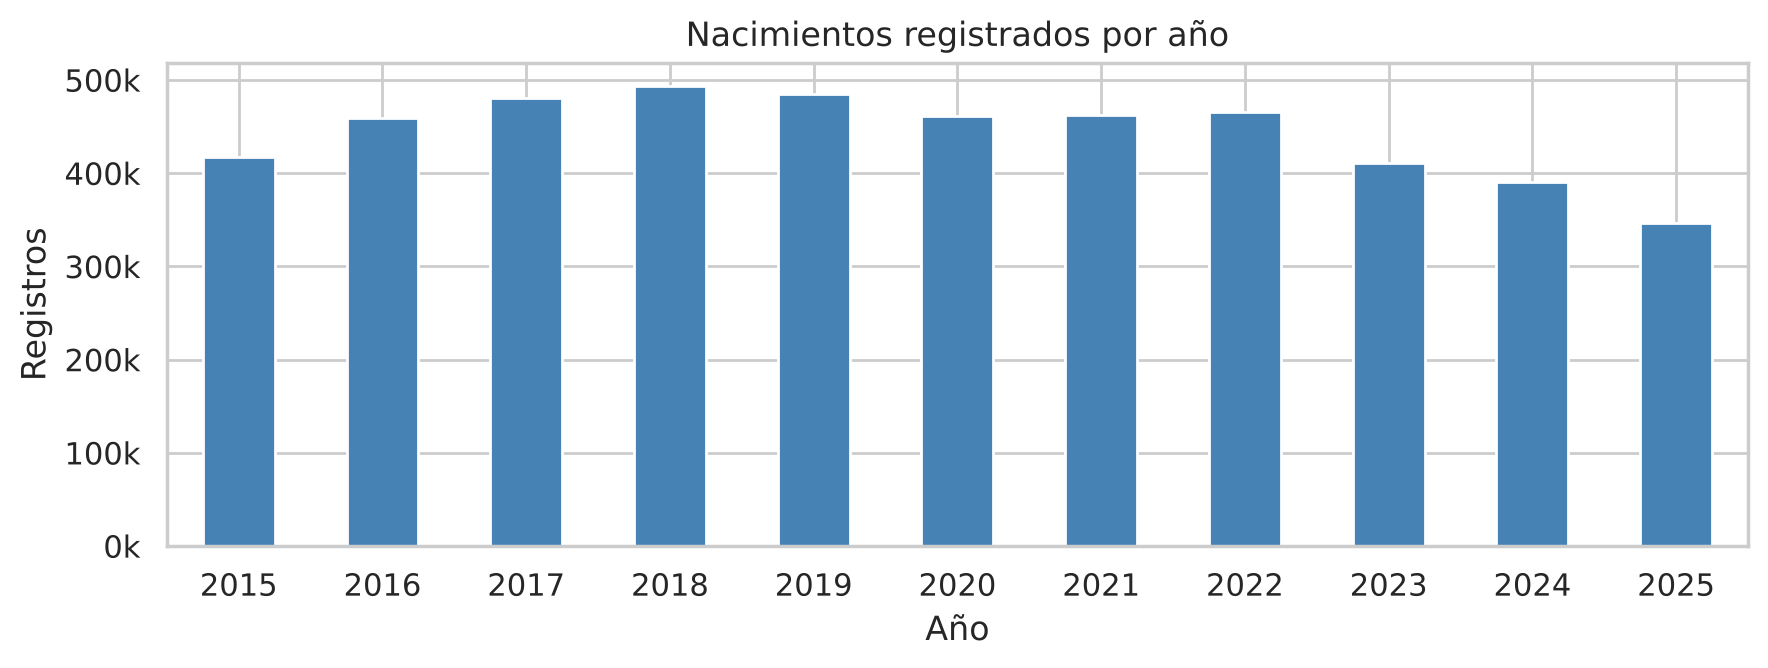

In [5]:
por_anio = df["FecNac_Año"].value_counts().sort_index()
print("Registros por año:"); print(por_anio.to_string())
print("\nRegistros por mes en 2025:")
print(df.loc[df["FecNac_Año"] == "2025", "FecNac_Mes"].value_counts().sort_index().to_string())
ax = por_anio.plot.bar(figsize=(9, 3.5), color="steelblue", rot=0)
ax.set_title("Nacimientos registrados por año"); ax.set_xlabel("Año"); ax.set_ylabel("Registros")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}k"))
guardar("registros_por_anio")

In [6]:
# Todas las categorías de las variables de baja cardinalidad (≤ 15 valores)
for c in df.columns:
    if df[c].nunique() <= 15:
        print(f"{c}: {sorted(df[c].cat.categories.astype(str).tolist())}")

FecNac_Año: ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
FecNac_Mes: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']


Condicion_Parto: ['CESAREA', 'EUTOCICO', 'IGNORADO', 'INSTRUMENTADO']
sexo_nacido: ['FEMENINO', 'IGNORADO', 'MASCULINO']
Tipo_Parto: ['DOBLE', 'IGNORADO', 'MAS DE TRES', 'TRIPLE', 'UNICO']
Estado_Civil: ['CASADO', 'CONVIVIENTE', 'DIVORCIADO', 'IGNORADO', 'SEPARADO', 'SOLTERO', 'VIUDO']
Nivel_Intrucción_Madre: ['IGNORADO', 'INCIAL/PRE-ESCOLAR', 'NINGUN NIVEL/ILETRADO', 'PRIMARIA COMPLETA', 'PRIMARIA INCOMPLETA', 'SECUNDARIA COMPLETA', 'SECUNDARIA INCOMPLETA', 'SUPERIOR NO UNIV. COMPLETA', 'SUPERIOR NO UNIV. INCOMPLETA', 'SUPERIOR UNIV. COMPLETA', 'SUPERIOR UNIV. INCOMPLETA']
Num_embar_madre: ['-1', '1', '2', '3', '4', '>=5']
Hijos_vivo_madre: ['-1', '1', '2', '3', '4', '>=5']


Hijos_fallec_madre: ['-1', '1', '2', '3', '4', '>=5']
nacmuer_abort_madre: ['1', '10', '11 a más', '2', '3', '4', '5', '6', '7', '8', '9', 'IGNORADO', 'NINGUNO']
Lugar_Nacido: ['CENTRO DE TRABAJO', 'DOMICILIO', 'ESTABLECIMIENTO DE SALUD', 'IGNORADO', 'OTRO', 'VIA PUBLICA']
Atiende_Parto: ['ENFERMERA(O)', 'FAMILIAR', 'IGNORADO', 'INTERNA(O)', 'MEDICO', 'MEDICO GINECO-OBSTETRA', 'NADIE(AUTOAYUDA)', 'OBSTETRA', 'OTRO', 'OTRO PROFESIONAL DE LA SALUD', 'PARTERA', 'PROMOTOR SALUD', 'TECNICO DE SALUD']


Financiador_Parto: ['ESSALUD', 'IGNORADO', 'PARTICULAR', 'PRIVADOS', 'SANIDAD EP', 'SANIDAD FAP', 'SANIDAD NAVAL', 'SANIDAD PNP', 'SIS']


In [7]:
# Problemas de formato
espacios = {c: int((df[c].cat.categories.astype(str) != df[c].cat.categories.astype(str).str.strip()).sum())
            for c in df.columns}
print("Categorías con espacios al inicio o al final:", {c: v for c, v in espacios.items() if v > 0})
print("Ejemplos:", [repr(x) for x in df["TALLA_NACIDO"].cat.categories[:3]], [repr(x) for x in df["Pais_Madre"].cat.categories[:3]])

ocup = df["DESC_OCUPACION"].astype(str)
mal = ocup.str.contains("Ð")
print(f"\nOcupaciones con el carácter 'Ð' (ñ mal codificada): {mal.sum():,} registros, "
      f"{df.loc[mal, 'DESC_OCUPACION'].nunique()} valores distintos. Ejemplos:")
print(df.loc[mal, "DESC_OCUPACION"].value_counts().head(3).to_string())

ubi = df["IdUbigeoInei"].astype(str).str.strip()
print(f"\nDistritos distintos en IdUbigeoInei (sin contar -1): {ubi[ubi != '-1'].nunique():,}")
print(f"Valores distintos en DESC_OCUPACION: {df['DESC_OCUPACION'].nunique():,}")
print(f"Proporción de 'AMA DE CASA' en DESC_OCUPACION: {(df['DESC_OCUPACION'] == 'AMA DE CASA').mean()*100:.1f}%")
print(f"\nPaíses distintos en Pais_Madre: {df['Pais_Madre'].nunique()}. Los 5 más frecuentes:")
print(df["Pais_Madre"].astype(str).str.strip().value_counts().head(5).to_string())
print(f"Registros con Ipress = 1: {(df['Ipress'].astype(str) == '1').sum():,}")

Categorías con espacios al inicio o al final: {'PESO_NACIDO': 626, 'TALLA_NACIDO': 72, 'DUR_EMB_PARTO': 1, 'Pais_Madre': 122}
Ejemplos: ["'-1'", "'047 '", "'048 '"] ["' ALEMANIA '", "' ARGENTINA '", "' BELICE '"]



Ocupaciones con el carácter 'Ð' (ñ mal codificada): 34,968 registros, 48 valores distintos. Ejemplos:
DESC_OCUPACION
PROFESOR DE ENSEÐANZA PRIMARIA                     27901
DISEÐADOR, GRAFICO                                  1952
PUBLICISTA, RESPONSABLE DE CAMPAÐA PUBLICITARIA     1363



Distritos distintos en IdUbigeoInei (sin contar -1): 1,892
Valores distintos en DESC_OCUPACION: 2,875
Proporción de 'AMA DE CASA' en DESC_OCUPACION: 83.8%

Países distintos en Pais_Madre: 127. Los 5 más frecuentes:


Pais_Madre
PERU         4755336
VENEZUELA     101607
COLOMBIA        3660
BOLIVIA         2463
ECUADOR         1664


Registros con Ipress = 1: 37,655


**Interpretación.** Cada afirmación se apoya en las salidas de las tres celdas anteriores:
- **Cobertura:** el registro cubre 11 años, de 2015 a 2025, con entre 346 mil (2025) y 494 mil (2018) nacimientos por año. 2025 tiene **0 registros en diciembre**, lo que coincide con el corte al 30/11 indicado en el nombre del archivo; por eso ese año tiene menos registros. La caída de 2023 y 2024 no se explica con los datos disponibles. Como el análisis trabaja con tasas, la sección 5 verifica si la prevalencia también cambia en el tiempo.
- **Espacios sobrantes:** afectan a `PESO_NACIDO` (626 categorías), `TALLA_NACIDO` (72) y `Pais_Madre` (122), por ejemplo `'047 '` o `' ALEMANIA '`.
- **Errata:** el nivel de instrucción tiene la categoría `INCIAL/PRE-ESCOLAR`.
- **Codificación:** 34 968 registros de ocupación tienen `Ð` en lugar de `Ñ` (por ejemplo, `ENSEÐANZA`).
- **Cardinalidad:** `DESC_OCUPACION` tiene 2875 valores, con 83.8% en "AMA DE CASA". `IdUbigeoInei` tiene 1892 distritos más el código `-1`, y `Pais_Madre` tiene 127 países, con Perú y Venezuela concentrando casi todos los registros.
- **Código sospechoso no documentado:** 37 655 registros tienen `Ipress = 1`. No afecta al modelo porque `Ipress` se excluye.

### 3.1 Rol de cada variable y criterios de selección

Las 22 columnas del CNV se evalúan con los mismos **seis criterios**. La decisión no se toma por el momento en que se conoce cada variable ni por el AUC global (que domina `DUR_EMB_PARTO`), sino por lo siguiente:

| # | Criterio | Pregunta | Cómo se mide en este EDA |
|---|---|---|---|
| 1 | **Validez** | ¿Existe cuando se usaría el modelo y no es consecuencia del parto ni una medida del recién nacido? | Diccionario de datos y cruce con el target (celda siguiente) |
| 2 | **Calidad** | ¿El dato es creíble y consistente? | Códigos de faltante, rangos, estabilidad por año, dependencia del faltante (secciones 4.1 a 4.7) |
| 3 | **Redundancia** | ¿Otra variable incluida ya lo dice? | Spearman y V de Cramér (sección 8) |
| 4 | **Asociación propia** | ¿Sigue asociada al bajo peso después de controlar por la duración del embarazo y por variables relacionadas? | Razón observada/esperada ajustada con IC95% (sección 7.2) |
| 5 | **Costo** | ¿Cuántas filas o categorías cuesta? | Casos completos (4.7) y cardinalidad (3) |
| 6 | **Uso** | ¿Es apropiada como entrada y qué decisión se tomaría con ella? | Decisión del equipo, declarada por escrito |

**Regla de decisión.** Una variable **entra** si pasa los criterios 1, 2 y 6 (requisitos) y además tiene asociación propia (4) sin ser redundante (3); el costo (5) desempata. **Sale** si falla un requisito, o si no tiene asociación propia y además cuesta (5) o es redundante (3). El umbral del criterio 4 es: al menos un contraste con razón ajustada ≥ 1.10 o ≤ 0.91 y con IC95% que excluya 1.

**Dependencia declarada.** La asociación se mide condicionando por la duración del embarazo, así que la lista de features vale mientras `DUR_EMB_PARTO` sea una entrada del modelo. Esa variable se conoce al momento del parto, no antes (ver sección 9). Si se exigiera una predicción estrictamente anterior al parto, el criterio 4 debe recalcularse sin ella.

**Decisión por columna** (la columna del dataset original va entre paréntesis cuando el nombre cambia):

| Variable | Decisión | Criterio | Evidencia |
|---|---|---|---|
| `PESO_NACIDO` | **Define el target** | — | Se usa solo para construir la variable objetivo `bajo_peso` (1 si < 2500 g); no es una entrada del modelo |
| `DUR_EMB_PARTO` | **Entra** | 1, 4 | Determinante principal: tasa de bajo peso de 97.6% (≤ 31 semanas) a 0.8% (≥ 41) y AUC univariado de 0.89 (secciones 7.2 y 9). Se registra al parto: dependencia declarada |
| `Tipo_Parto` | **Entra** | 1, 4 | Se conoce por ecografía; razón ajustada por duración de 1.55 (sección 7.2) |
| `departamento` (de `IdUbigeoInei`) | **Entra** | 2, 4, 5 | 1892 distritos agregados a 25 departamentos; razón observada/esperada de 0.69 a 1.48 tras ajustar por duración |
| `Edad_Madre` → `edad_grupo` | **Entra** | 4 | Factor materno clásico; tras ajustar, lo que sobrevive del efecto en U es el grupo de ≤ 17 años (1.21) |
| `Num_embar_madre` | **Entra** | 3, 4 | Absorbe a `Hijos_vivo_madre`; primigestas con razón ajustada de 1.19 frente al segundo embarazo |
| `Nivel_Intrucción_Madre` → `Nivel_Instruccion` | **Entra** | 4 | Proxy socioeconómico materno; razón ajustada de 1.27 (≤ primaria frente a secundaria completa) |
| `Financiador_Parto` | **Entra** | 4 (cautela en 1) | Proxy socioeconómico por afiliación al seguro; razón ajustada de 1.21 (SIS frente a privado). Se registra con el certificado, no antes del parto: se declara |
| `sexo_nacido` | **Entra** | 4 (cautela en 1) | Razón ajustada de 1.20 (mujer frente a varón). Es una característica del recién nacido conocible por ecografía: se declara |
| `Pais_Madre` → `pais_grupo` | **Entra** | 1–5; 6 por decisión del equipo | Venezuela frente a Perú: razón ajustada de 1.20 con duración, edad, financiador y departamento (sección 7.2). Es un marcador de contexto, no un efecto de la nacionalidad |
| `nacmuer_abort_madre` | **Sale** | 2 y 5 | Faltante de 8.6% no aleatorio por departamento y causa del 79% de las filas perdidas con casos completos (sección 4.7). No sale por falta de asociación: su efecto crudo se invierte al condicionar por duración (sección 7.2) |
| `TALLA_NACIDO` | **Sale** | 1 | Co-resultado del peso (ρ = 0.72, celda siguiente); además tiene errores de registro (sección 4.3) |
| `Ipress` | **Sale** | 1 y 5 | Causalidad inversa por triaje (los hospitales de referencia concentran embarazos de riesgo) y alta cardinalidad |
| `Atiende_Parto`, `Condicion_Parto`, `Lugar_Nacido` | **Salen** | 1 | Se definen durante el parto y dependen del riesgo percibido (celda siguiente) |
| `Hijos_vivo_madre` | **Sale** | 3 | Redundante con `Num_embar_madre`, ρ = 0.88 (sección 8) |
| `Hijos_fallec_madre` | **Sale** | 2 | 97% de `-1` con significado ambiguo (sección 4.2) |
| `Estado_Civil` | **Sale** | 2 | Poco creíble y con faltante dependiente de la edad (sección 4.6) |
| `DESC_OCUPACION` | **Sale** | 2 | Texto libre con 2875 valores y 84% en "AMA DE CASA" (sección 3). Su versión agrupada no se evaluó con el criterio 4 |
| `FecNac_Año` | **Fuera del modelo** | — | No es un predictor: se usa solo para la partición temporal (sección 5) |
| `FecNac_Mes` | **Sale** | 4 (pendiente) | Sin señal marginal (AUC univariado cercano a 0.50, sección 9); su asociación condicional no se evaluó |


In [8]:
peso_tmp = pd.to_numeric(df["PESO_NACIDO"].astype(str).str.strip(), errors="coerce")
talla_tmp = pd.to_numeric(df["TALLA_NACIDO"].astype(str).str.strip(), errors="coerce")
validos_pt = peso_tmp.between(500, 6000) & talla_tmp.between(20, 65)
print(f"Correlación de Spearman entre TALLA_NACIDO y PESO_NACIDO: "
      f"{peso_tmp[validos_pt].corr(talla_tmp[validos_pt], method='spearman'):.3f}")

bp_tmp = (peso_tmp < 2500)[peso_tmp.between(500, 6000)]
for c in ["Condicion_Parto", "Lugar_Nacido", "Atiende_Parto"]:
    t = bp_tmp.groupby(df.loc[bp_tmp.index, c], observed=True).agg(["mean", "count"])
    t.columns = ["tasa_bajo_peso", "n"]; t["tasa_bajo_peso"] *= 100
    print(f"\n{c}:"); print(t.sort_values("tasa_bajo_peso", ascending=False).round(2).to_string())
del peso_tmp, talla_tmp, bp_tmp

Correlación de Spearman entre TALLA_NACIDO y PESO_NACIDO: 0.722



Condicion_Parto:
                 tasa_bajo_peso        n
Condicion_Parto                         
IGNORADO                 10.180    15387
CESAREA                   9.470  1872765
INSTRUMENTADO             5.490     6936
EUTOCICO                  4.410  2976398



Lugar_Nacido:
                          tasa_bajo_peso        n
Lugar_Nacido                                     
VIA PUBLICA                       17.400     2621
IGNORADO                          10.980      246
DOMICILIO                          7.460    57619
ESTABLECIMIENTO DE SALUD           6.370  4780277
CENTRO DE TRABAJO                  4.880     1843
OTRO                               4.720    28880



Atiende_Parto:
                              tasa_bajo_peso        n
Atiende_Parto                                        
NADIE(AUTOAYUDA)                      16.430     2417
FAMILIAR                               9.810    41249
OTRO                                   9.390     5974
MEDICO GINECO-OBSTETRA                 9.230  1838058
MEDICO                                 8.660   449970
OTRO PROFESIONAL DE LA SALUD           8.000     1726
ENFERMERA(O)                           7.550     2464
PROMOTOR SALUD                         6.650      421
IGNORADO                               6.630     4613
PARTERA                                5.980    18929
TECNICO DE SALUD                       4.110     9732
OBSTETRA                               3.800  2485434
INTERNA(O)                             3.070    10499


**Interpretación.**
- `TALLA_NACIDO` tiene una correlación de 0.72 con el peso. Es un co-resultado: se mide en el mismo momento y refleja el mismo crecimiento fetal que el peso, así que usarla equivaldría a predecir el peso con otra medida del mismo recién nacido.
- Las variables del parto también se asocian fuertemente al resultado: la cesárea tiene 9.5% de bajo peso frente a 4.4% del parto eutócico; el parto en vía pública, 17.4%; y el parto sin asistencia, 16.4%. Parte de esa asociación es causalidad inversa: un feto con bajo peso o prematuro tiene más probabilidad de nacer por cesárea o de ser atendido por un especialista.

Esto confirma la exclusión por el criterio 1: estas variables se definen durante el parto o describen el desenlace, así que incluirlas inflaría las métricas con información que no existe antes del parto.


## 4. Calidad de datos

### 4.1 Códigos de valor faltante

El CNV no usa celdas vacías: los faltantes vienen codificados como `IGNORADO`, `-1` o `99`, según la variable. Por eso `isna()` reporta cero y hay que contarlos explícitamente.

In [9]:
def contar_codigos(s):
    cats = s.cat.categories.astype(str).str.strip().str.upper()
    t = pd.Series(cats[s.cat.codes.to_numpy()])
    return pd.Series({"IGNORADO": (t == "IGNORADO").sum(), "-1": (t == "-1").sum(),
                      "99": (t == "99").sum(), "NaN": s.isna().sum()})

codigos = df.apply(contar_codigos).T
codigos["total"] = codigos.sum(axis=1)
codigos["pct"] = codigos["total"] / len(df) * 100
codigos[codigos["total"] > 0].sort_values("pct", ascending=False)

,IGNORADO,-1,99,NaN,total,pct
Hijos_fallec_madre,0,4726940,0,0,4726940,96.973
nacmuer_abort_madre,417502,0,0,0,417502,8.565
Estado_Civil,202327,0,0,0,202327,4.151
Num_embar_madre,0,49841,0,0,49841,1.022
Financiador_Parto,38679,0,0,0,38679,0.793
Hijos_vivo_madre,0,37530,0,0,37530,0.770
Condicion_Parto,15463,0,0,0,15463,0.317
IdUbigeoInei,0,8640,0,0,8640,0.177
Tipo_Parto,8374,0,0,0,8374,0.172
TALLA_NACIDO,0,4697,1,0,4698,0.096


**Interpretación.** La columna `NaN` es cero en todas las variables, así que `isna()` no detectaría ningún faltante. Los códigos especiales sí aparecen:
- `Hijos_fallec_madre` tiene **97% de `-1`**. Si se tratara como faltante, un análisis de casos completos eliminaría casi todo el dataset. La sección 4.2 analiza qué significa realmente.
- `nacmuer_abort_madre` (8.6% `IGNORADO`) y `Estado_Civil` (4.2%) son los únicos faltantes relevantes. El resto está por debajo de 1.1%. La sección 4.7 muestra que el faltante de `nacmuer_abort_madre` no es aleatorio y que es la principal causa de pérdida de filas, por lo que esa variable se excluye.
- `DUR_EMB_PARTO = 99` aparece en 19 registros. El diccionario de datos no menciona este código, pero la sección 4.3 muestra que 99 está aislado del resto de valores, lo que indica que es un código de "ignorado".


### 4.2 ¿Qué significa `-1` en la historia obstétrica?

El diccionario dice que `-1` significa "ignorado", pero las variables de conteo no tienen la opción `0`. Para decidir cómo tratarlo, se cruza cada variable con el número de embarazos.

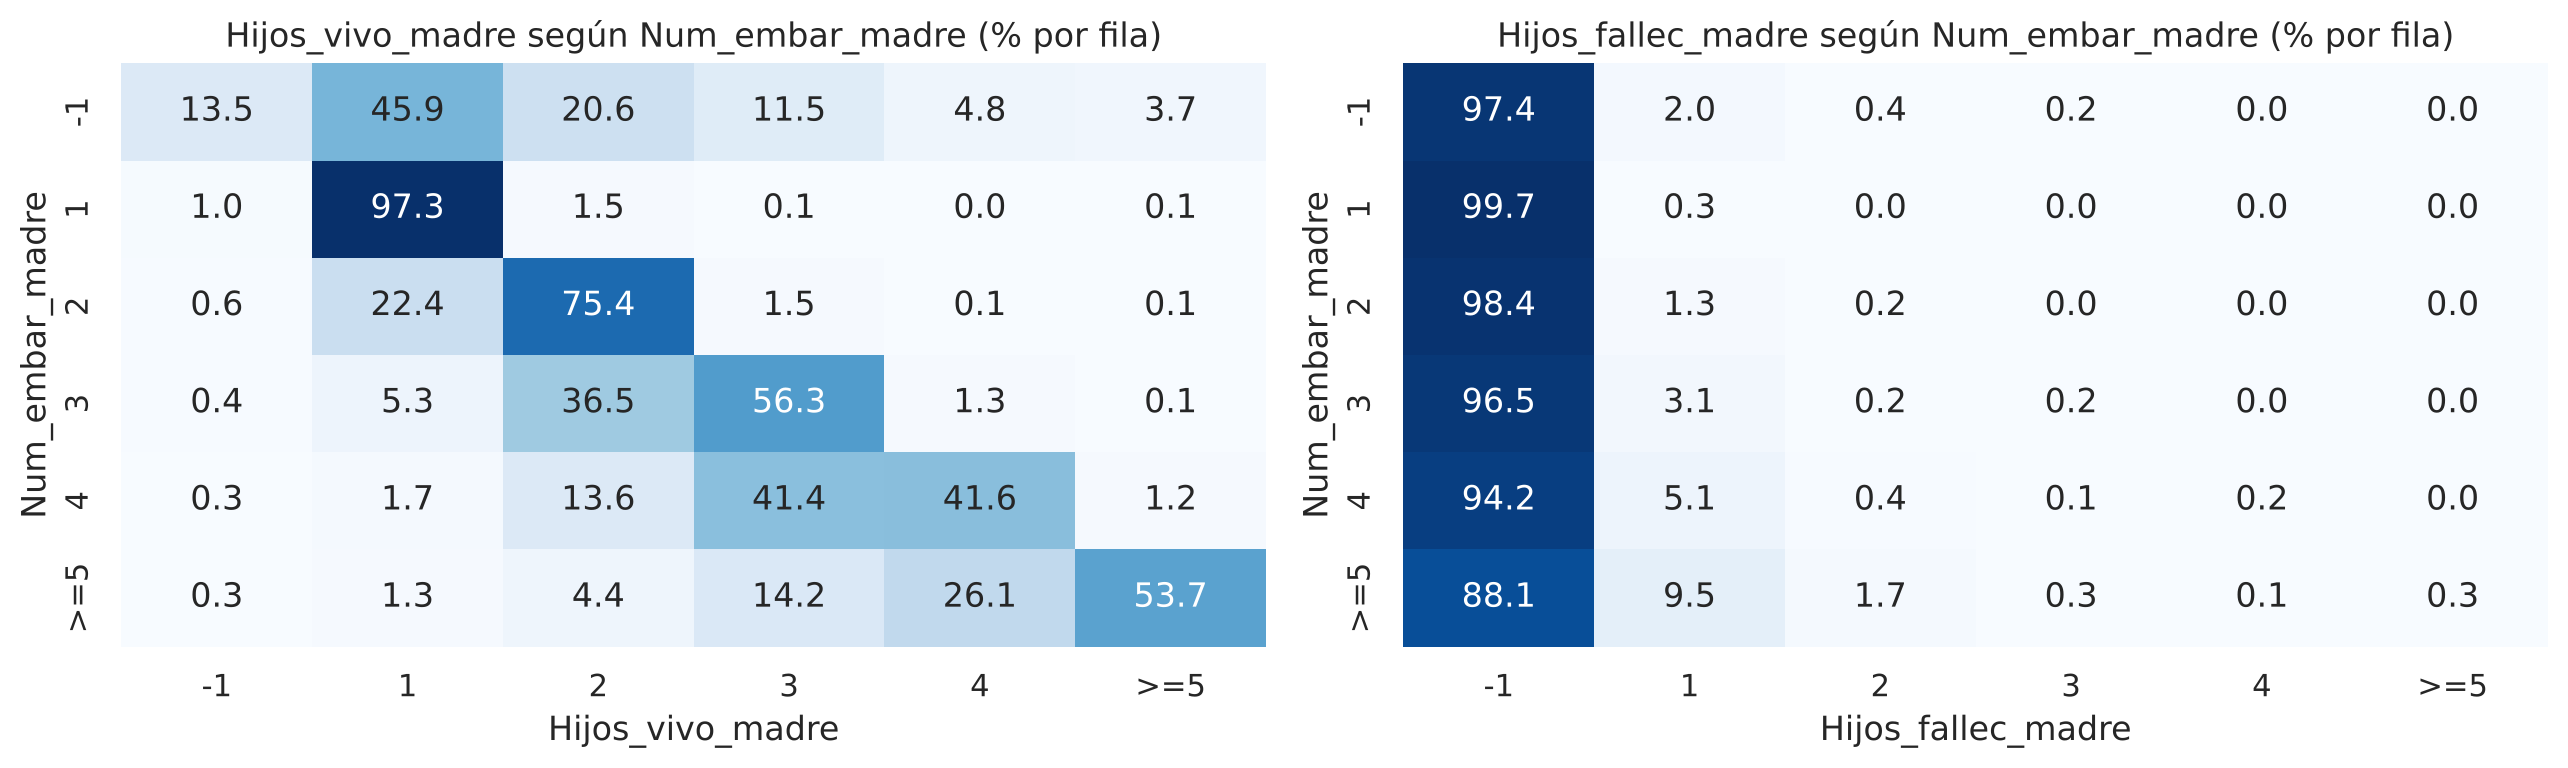

In [10]:
orden = ["-1", "1", "2", "3", "4", ">=5"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["Hijos_vivo_madre", "Hijos_fallec_madre"]):
    ct = pd.crosstab(df["Num_embar_madre"], df[col], normalize="index").reindex(index=orden, columns=orden) * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{col} según Num_embar_madre (% por fila)")
guardar("semantica_menos1")

**Interpretación.** El diccionario de datos define las tres variables como conteos con valores `-1 (ignorado), 1, 2, 3, 4, >=5`: **ninguna tiene la opción 0**. Además, describe `Num_embar_madre` como el número de embarazos "previos".

- **`Num_embar_madre` incluye el embarazo actual, contra lo que indica el diccionario.** Si contara solo embarazos previos, las madres primerizas no tendrían un valor válido, porque no existe el 0, y deberían figurar como `-1`. Sin embargo, `-1` aparece solo en el 1.0% de los registros (sección 4.1), mientras que el valor 1 agrupa al 30%. Las primerizas, por tanto, están registradas como 1. Por la misma razón, `Hijos_vivo_madre` incluye al recién nacido, lo que explica la diagonal dominante del gráfico izquierdo.
- **En `Num_embar_madre` y `Hijos_vivo_madre`, `-1` es faltante:** es poco frecuente (1.0% y 0.8%) y tiende a aparecer en ambas variables a la vez, como ocurre cuando el campo se deja en blanco.
- **En `Hijos_fallec_madre`, el significado de `-1` es ambiguo.** Aparece en el 97% de los registros y en el 99.7% de las primigestas, que no pueden tener hijos fallecidos previos, lo que sugiere que la mayoría de esos valores significa "ninguno". Pero no hay forma de distinguir, dentro de ese 97%, a las madres sin hijos fallecidos de aquellas cuyo dato no se registró.

**Decisión:** `Hijos_fallec_madre` se excluye. Recodificar `-1` a 0 asumiría un valor que no puede verificarse, y reconstruirlo con la identidad acumularía los errores de tres variables. En `Num_embar_madre` y `Hijos_vivo_madre`, `-1` pasa a `NaN`.

### 4.3 Valores fuera de rango en variables numéricas

In [11]:
def cat_a_num(s, mapa=None):
    """Convierte una columna 'category' a número trabajando sobre sus categorías (rápido en 4.9 M filas)."""
    cats = pd.Series(s.cat.categories.astype(str).str.strip())
    if mapa:
        cats = cats.replace(mapa)
    vals = pd.to_numeric(cats, errors="coerce").to_numpy(dtype=float)
    codes = s.cat.codes.to_numpy()
    out = np.where(codes >= 0, vals[codes], np.nan)
    return pd.Series(out, index=s.index)

num_raw = pd.DataFrame({c: cat_a_num(df[c]) for c in ["PESO_NACIDO", "TALLA_NACIDO", "DUR_EMB_PARTO", "Edad_Madre"]})
display(num_raw.describe(percentiles=[.001, .01, .5, .99, .999]).T)

RANGOS = {"PESO_NACIDO": (500, 6000), "TALLA_NACIDO": (20, 65), "DUR_EMB_PARTO": (20, 45), "Edad_Madre": (10, 55)}
fuera_rango = pd.DataFrame({
    c: {"rango_valido": f"{lo}–{hi}", "fuera_de_rango": int(((num_raw[c] < lo) | (num_raw[c] > hi)).sum())}
    for c, (lo, hi) in RANGOS.items()}).T
fuera_rango["pct"] = fuera_rango["fuera_de_rango"].astype(int) / len(df) * 100
display(fuera_rango)

for c, (lo, hi) in RANGOS.items():
    x = num_raw[c]
    print(f"\n{c} — valores por debajo de {lo}:", x[x < lo].value_counts().sort_index().head(12).to_dict())
    print(f"{c} — valores por encima de {hi}:", x[x > hi].value_counts().sort_index().tail(12).to_dict())

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
PESO_NACIDO,"4,874,510.000","3,248.093",528.733,-1.000,610.000,"1,552.000","3,270.000","4,400.000","4,887.000","8,000.000"
TALLA_NACIDO,"4,874,510.000",49.103,5.488,-1.000,25.000,39.500,49.500,54.000,56.000,"5,334.000"
DUR_EMB_PARTO,"4,874,510.000",38.620,1.721,3.000,25.000,32.000,39.000,41.000,42.000,99.000
Edad_Madre,"4,874,510.000",28.298,6.938,0.000,14.000,16.000,28.000,43.000,47.000,62.000


,rango_valido,fuera_de_rango,pct
PESO_NACIDO,500–6000,3024,0.062
TALLA_NACIDO,20–65,4729,0.097
DUR_EMB_PARTO,20–45,20,0.000
Edad_Madre,10–55,102,0.002



PESO_NACIDO — valores por debajo de 500: {-1.0: 1315, 30.0: 1, 100.0: 1, 300.0: 558, 301.0: 1, 302.0: 3, 303.0: 2, 304.0: 5, 305.0: 8, 306.0: 1, 307.0: 3, 308.0: 2}
PESO_NACIDO — valores por encima de 6000: {6400.0: 2, 6420.0: 1, 6460.0: 1, 6495.0: 1, 6510.0: 1, 6556.0: 1, 6590.0: 1, 6970.0: 1, 7000.0: 1, 7003.0: 1, 7010.0: 1, 8000.0: 2}

TALLA_NACIDO — valores por debajo de 20: {-1.0: 4697}
TALLA_NACIDO — valores por encima de 65: {80.0: 4, 80.4: 1, 81.0: 1, 82.0: 2, 84.6: 1, 88.5: 1, 92.0: 1, 99.0: 1, 4905.0: 1, 5046.0: 1, 5250.0: 1, 5334.0: 1}

DUR_EMB_PARTO — valores por debajo de 20: {3.0: 1}
DUR_EMB_PARTO — valores por encima de 45: {99.0: 19}

Edad_Madre — valores por debajo de 10: {0.0: 30, 1.0: 3, 2.0: 5, 3.0: 4, 4.0: 4, 5.0: 2, 7.0: 1, 8.0: 2, 9.0: 4}
Edad_Madre — valores por encima de 55: {56.0: 19, 57.0: 8, 58.0: 7, 59.0: 7, 60.0: 5, 62.0: 1}


**Interpretación.** Los rangos se eligieron mirando dónde se cortan las distribuciones, que se ven en las listas de valores extremos:
- **`PESO_NACIDO`:** por debajo de 500 g aparecen el código `-1` (1315 registros) y un grupo anómalo de 558 registros con exactamente 300 g, más varios entre 301 y 308 g. Es probable que sean errores de digitación, por ejemplo 3000 g sin un cero, aunque no se puede confirmar. Por encima de 6000 g hay valores aislados de hasta 8000 g. En total quedan fuera 3024 registros (0.06%).
- **`TALLA_NACIDO`:** el código `-1` aparece 4697 veces, hay tallas de 80 a 99 cm y valores como 4905 o 5334, que parecen tallas de 49.05 o 53.34 cm sin el punto decimal. No se usa como feature.
- **`DUR_EMB_PARTO`:** hay un registro con 3 semanas y 19 con 99, aislados del rango 20–43.
- **`Edad_Madre`:** hay 55 registros con edades de 0 a 9 años, imposibles, y 47 entre 56 y 62 años, extremadamente improbables.

**Decisión:** menos del 0.1% de los registros queda fuera de rango. Esos valores pasan a `NaN`, y los registros sin peso válido se eliminan en el preprocesamiento porque no tienen target.

### 4.4 Duplicados

In [12]:
dup = df.duplicated(keep=False)
print(f"Filas idénticas en las 22 columnas: {df.duplicated().sum():,} ({df.duplicated().mean()*100:.3f}%)")
print("\nTipo_Parto entre los registros duplicados (proporción):")
print(df.loc[dup, "Tipo_Parto"].value_counts(normalize=True).round(3).head().to_string())

Filas idénticas en las 22 columnas: 974 (0.020%)

Tipo_Parto entre los registros duplicados (proporción):
Tipo_Parto
UNICO         0.909
DOBLE         0.084
TRIPLE        0.008
IGNORADO      0.000
MAS DE TRES   0.000


**Interpretación.** Hay 974 filas idénticas (0.02%). El dataset no tiene un identificador único, así que no es posible distinguir un error de registro de dos nacimientos distintos con los mismos atributos. El 8.4% de estos duplicados son partos dobles, lo que sugiere que al menos parte son nacimientos reales.

**Decisión:** se mantienen. Su efecto sobre el análisis es despreciable y eliminarlos podría borrar nacimientos legítimos.

### 4.5 Consistencia entre variables

Se verifican combinaciones que no deberían ocurrir: más hijos vivos que embarazos, y madres muy jóvenes con muchos embarazos.

In [13]:
ne = cat_a_num(df["Num_embar_madre"], {">=5": "5", "-1": "nan"})
hv = cat_a_num(df["Hijos_vivo_madre"], {">=5": "5", "-1": "nan"})
inc = (hv > ne) & (ne < 5)          # con ">=5" no se puede comparar
print(f"Registros con Hijos_vivo_madre > Num_embar_madre: {inc.sum():,} ({inc.mean()*100:.2f}%)")
print("Tipo_Parto en esos registros (proporción):")
print(df.loc[inc, "Tipo_Parto"].value_counts(normalize=True).round(3).to_string())
inc_unico = inc & (df["Tipo_Parto"] == "UNICO")
print(f"→ inconsistentes y con parto único (no explicables por gemelos): {inc_unico.sum():,} ({inc_unico.mean()*100:.2f}%)")

joven = (num_raw["Edad_Madre"] <= 15) & (ne >= 4)
print(f"\nMadres de 15 años o menos con 4 o más embarazos: {joven.sum():,}")

Registros con Hijos_vivo_madre > Num_embar_madre: 67,291 (1.38%)
Tipo_Parto en esos registros (proporción):
Tipo_Parto
DOBLE         0.549
UNICO         0.437
TRIPLE        0.013
IGNORADO      0.001
MAS DE TRES   0.000
→ inconsistentes y con parto único (no explicables por gemelos): 29,392 (0.60%)

Madres de 15 años o menos con 4 o más embarazos: 106


**Interpretación.**
- **Más hijos vivos que embarazos:** hay 67 291 registros (1.38%) en esta situación. El 55% corresponde a partos dobles, donde es esperable: una primigesta con gemelos tiene un embarazo y dos hijos vivos. Pero **29 392 registros (0.60%) son partos únicos**, y en ellos la combinación es imposible. Al menos uno de los dos campos está mal registrado, y no se puede saber cuál.
- **Madres muy jóvenes con muchos embarazos:** hay 106 madres de 15 años o menos con cuatro o más embarazos. Es improbable pero no imposible.

**Decisión:** se mantienen ambos grupos. El impacto es menor al 0.7% y no hay forma de corregirlos. Sin embargo, el registro tiene errores también en la historia obstétrica, y esto se reporta como limitación.

### 4.6 Consistencia de registro: `Estado_Civil`

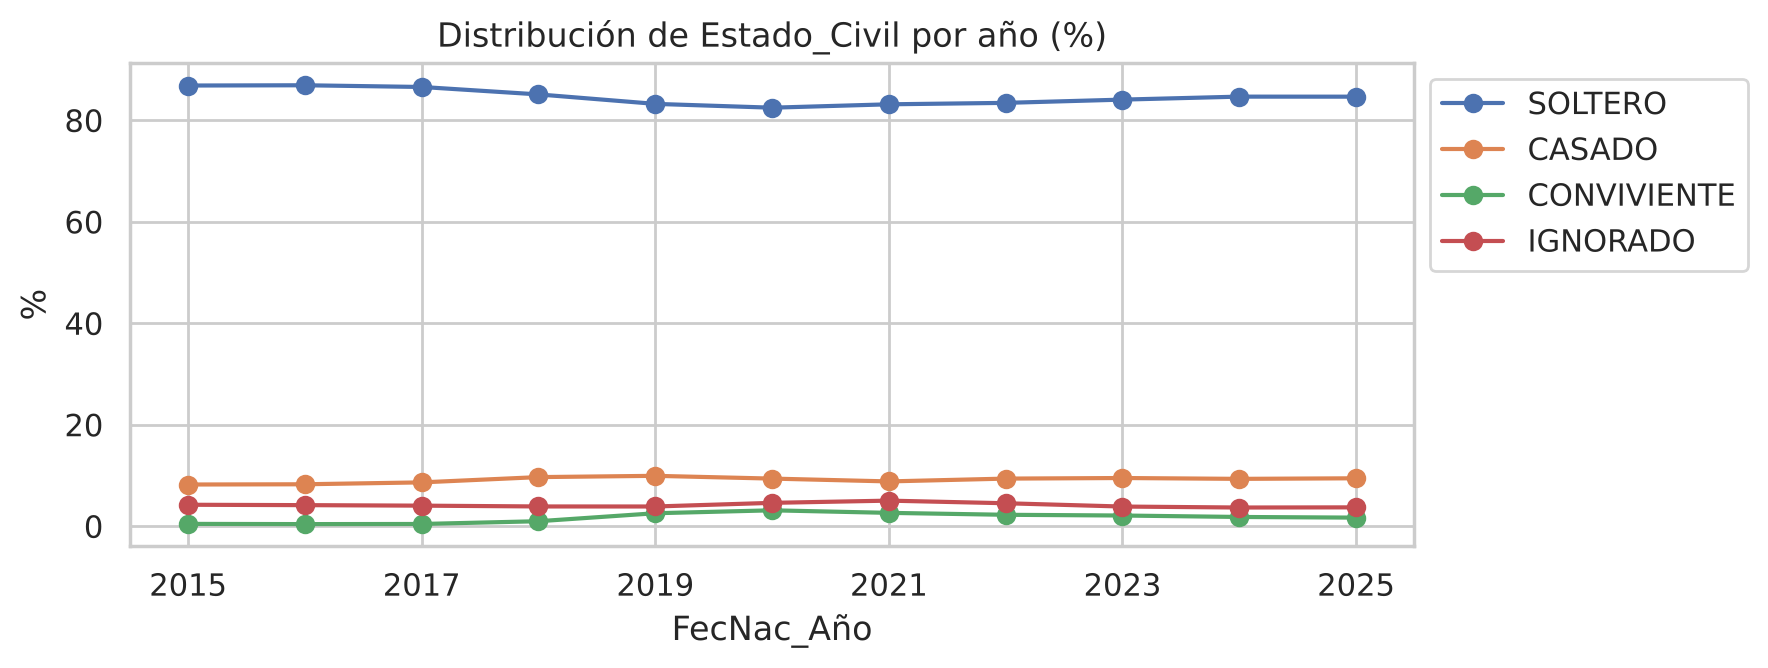

Estado_Civil,CASADO,CONVIVIENTE,DIVORCIADO,IGNORADO,SOLTERO,VIUDO,SEPARADO
FecNac_Año,,,,,,,
2015,8.200,0.400,0.300,4.200,86.800,0.000,0.000
2016,8.200,0.400,0.300,4.100,86.900,0.000,0.000
2017,8.600,0.400,0.300,4.000,86.500,0.000,0.000
2018,9.700,1.000,0.400,3.900,85.100,0.000,0.000
2019,9.900,2.500,0.400,3.900,83.200,0.000,0.000
2020,9.400,3.100,0.400,4.600,82.500,0.000,0.000
2021,8.800,2.600,0.400,5.000,83.100,0.000,0.000
2022,9.400,2.200,0.400,4.500,83.400,0.000,0.000
2023,9.500,2.100,0.500,3.900,84.100,0.000,0.000


Estado_Civil según grupo de edad de la madre (% por fila):


Estado_Civil,CASADO,CONVIVIENTE,DIVORCIADO,IGNORADO,SOLTERO,VIUDO,SEPARADO
Edad_Madre,,,,,,,
≤17,0.100,1.200,0.000,78.700,20.100,0.000,0.000
18–24,1.200,2.400,0.000,1.900,94.500,0.000,0.000
25–34,10.100,1.700,0.300,0.000,87.900,0.000,0.000
≥35,19.700,0.800,1.200,0.000,78.200,0.100,0.000


In [14]:
ec = pd.crosstab(df["FecNac_Año"], df["Estado_Civil"], normalize="index") * 100
ax = ec[["SOLTERO", "CASADO", "CONVIVIENTE", "IGNORADO"]].plot(figsize=(9, 3.5), marker="o")
ax.set_title("Distribución de Estado_Civil por año (%)"); ax.set_ylabel("%"); ax.legend(bbox_to_anchor=(1, 1))
guardar("estado_civil_por_anio")
display(ec.round(1))

grupo_tmp = pd.cut(num_raw["Edad_Madre"], [9, 17, 24, 34, 55], labels=["≤17", "18–24", "25–34", "≥35"])
print("Estado_Civil según grupo de edad de la madre (% por fila):")
display((pd.crosstab(grupo_tmp, df["Estado_Civil"], normalize="index") * 100).round(1))

**Interpretación.**
- Entre 83% y 87% de las madres figuran como "soltera" en todos los años, y solo entre 0.4% y 3.1% como "conviviente". La categoría "conviviente" sube de 0.4% a 3.1% entre 2017 y 2020 sin un cambio equivalente en otras categorías, lo que apunta a un cambio en la forma de registro y no a un cambio demográfico.
- La tabla por edad muestra el problema más grave: **el 78.7% de las madres de 17 años o menos tiene `Estado_Civil = IGNORADO`**, frente a 0% en las mayores de 25. El faltante depende de la edad, que es justamente un factor de riesgo (sección 7). Eliminar los casos incompletos de esta variable eliminaría a la mayoría de las madres adolescentes.

**Decisión:** `Estado_Civil` se excluye del modelo por tres razones (criterio 2, calidad):
1. **Baja validez:** la distribución (≈ 85% "soltero") y el salto de "conviviente" entre 2017 y 2020 indican que la variable refleja la práctica de registro más que el estado civil real.
2. **Faltante dependiente de la edad:** el 78.7% de las madres de 17 años o menos no tiene el dato. Eliminar esos casos excluiría a la mayoría de un grupo de alto riesgo (sección 7), y agruparlos en "desconocido" haría que la variable funcione como un indicador indirecto de la edad.
3. **Precedente con el mismo dataset:** Andrade-Girón et al. (2026), que trabajan con el CNV, tampoco la incluyen entre sus predictores. Almeida et al. (2026) sí la usan, pero con datos del SINASC, donde la variable no presenta estos problemas. Esta diferencia se reporta como limitación frente al paper de referencia.

### 4.7 Limpieza mínima para el análisis exploratorio

Se crea `df_eda`, una copia limpia **solo para que los gráficos sean correctos**. No incluye codificación, escalado ni imputación: eso se hace en `src/preprocessing.py` después de la partición. Reglas aplicadas, todas justificadas en las secciones 4.1 a 4.3:

- `IGNORADO` pasa a `NaN` en todas las variables categóricas.
- `-1` pasa a `NaN` en `Num_embar_madre`, `Hijos_vivo_madre` e `IdUbigeoInei`.
- `Hijos_fallec_madre` no se incluye en `df_eda` (ver 4.2).
- `nacmuer_abort_madre` tampoco se incluye: está excluida del modelo. Su faltante se evalúa aparte, con los datos originales, en la segunda celda de esta sección.
- `>=5` se trata como 5 en `Num_embar_madre` y `Hijos_vivo_madre`.
- Los valores fuera de los rangos de la sección 4.3 pasan a `NaN`.
- `departamento` se deriva de los dos primeros dígitos del ubigeo de residencia de la madre.
- `pais_grupo` agrupa `Pais_Madre` en Perú, Venezuela y Otro, porque los demás países tienen muy pocos registros (ver sección 3).
- `FecNac_Mes` se convierte a número solo para evaluar su señal marginal (sección 9).

La lista de las **9 features del modelo** se define aquí y se justifica en la sección 3.1. La tabla de flujo de filas muestra cuántos registros quedan en cada paso del preprocesamiento.


In [15]:
DEPARTAMENTOS = {
    "01": "Amazonas", "02": "Áncash", "03": "Apurímac", "04": "Arequipa", "05": "Ayacucho",
    "06": "Cajamarca", "07": "Callao", "08": "Cusco", "09": "Huancavelica", "10": "Huánuco",
    "11": "Ica", "12": "Junín", "13": "La Libertad", "14": "Lambayeque", "15": "Lima",
    "16": "Loreto", "17": "Madre de Dios", "18": "Moquegua", "19": "Pasco", "20": "Piura",
    "21": "Puno", "22": "San Martín", "23": "Tacna", "24": "Tumbes", "25": "Ucayali"}

def limpiar_cat(s, nulos=("IGNORADO",), mapa=None):
    d = {}
    for c in s.cat.categories:
        v = str(c).strip()
        v = (mapa or {}).get(v, v)
        d[c] = np.nan if v in nulos else v
    return s.map(d).astype("category")

df_eda = pd.DataFrame(index=df.index)

for c, (lo, hi) in RANGOS.items():
    x = num_raw[c]
    df_eda[c] = x.where(x.between(lo, hi))

for c in ["Tipo_Parto", "Estado_Civil", "Financiador_Parto", "sexo_nacido"]:
    df_eda[c] = limpiar_cat(df[c])
df_eda["Nivel_Instruccion"] = limpiar_cat(df["Nivel_Intrucción_Madre"],
                                          mapa={"INCIAL/PRE-ESCOLAR": "INICIAL/PRE-ESCOLAR"})

df_eda["Num_embar_madre"]     = cat_a_num(df["Num_embar_madre"],    {">=5": "5", "-1": "nan"})
df_eda["Hijos_vivo_madre"]    = cat_a_num(df["Hijos_vivo_madre"],   {">=5": "5", "-1": "nan"})
df_eda["FecNac_Mes"]          = cat_a_num(df["FecNac_Mes"])

ubi = df["IdUbigeoInei"].astype(str).str.strip()
df_eda["departamento"] = ubi.where(ubi != "-1").str.zfill(6).str[:2].map(DEPARTAMENTOS).astype("category")
pais = df["Pais_Madre"].astype(str).str.strip()
df_eda["pais_grupo"] = pais.where(pais.isin(["PERU", "VENEZUELA"]), "OTRO").astype("category")
df_eda["anio"] = df["FecNac_Año"].astype(int)

df_eda["bajo_peso"] = np.where(df_eda["PESO_NACIDO"].isna(), np.nan, (df_eda["PESO_NACIDO"] < 2500).astype(float))

faltantes_eda = (df_eda.isna().mean() * 100).sort_values(ascending=False)
print("% de faltantes tras la limpieza mínima:")
print(faltantes_eda.round(2).to_string())

# Features del modelo final (9). edad_grupo se deriva de Edad_Madre en la sección 7 y tiene los mismos faltantes.
FEATS = ["DUR_EMB_PARTO", "Tipo_Parto", "departamento", "Edad_Madre", "Num_embar_madre",
         "Nivel_Instruccion", "Financiador_Parto", "sexo_nacido", "pais_grupo"]

valido = df_eda["bajo_peso"].notna()
print("% de faltantes de las 9 features (sobre los registros con peso válido):")
print((df_eda.loc[valido, FEATS].isna().mean() * 100).round(2).sort_values(ascending=False).to_string())

# Flujo de filas del preprocesamiento
completos = valido & df_eda[FEATS].notna().all(axis=1)
n_raw, n_valido, n_comp = len(df_eda), int(valido.sum()), int(completos.sum())
n_pre = int((completos & (df_eda["anio"] <= 2023)).sum())
n_test = int((completos & (df_eda["anio"] >= 2024)).sum())
flujo = pd.DataFrame({
    "paso": ["CNV cargado y reparado", "limpiar(): se eliminan los registros sin peso válido",
             "seleccionar_features(): casos completos con las 9 features",
             "   de ellos, 2015–2023 (train 80 % + validación 20 %)", "   de ellos, 2024–2025 (test)"],
    "filas": [n_raw, n_valido, n_comp, n_pre, n_test]})
flujo["% del paso anterior"] = [np.nan, n_valido / n_raw * 100, n_comp / n_valido * 100, n_pre / n_comp * 100, n_test / n_comp * 100]
display(flujo.style.format({"filas": "{:,.0f}", "% del paso anterior": "{:.2f}"}, na_rep="—").hide(axis="index"))
print(f"Train ≈ {n_pre*0.8:,.0f} | validación ≈ {n_pre*0.2:,.0f} | test = {n_test:,}")


% de faltantes tras la limpieza mínima:
Estado_Civil        4.150
Num_embar_madre     1.020
Financiador_Parto   0.790
Hijos_vivo_madre    0.770
departamento        0.180
Tipo_Parto          0.170
TALLA_NACIDO        0.100
PESO_NACIDO         0.060
bajo_peso           0.060
Nivel_Instruccion   0.050
sexo_nacido         0.000
Edad_Madre          0.000
DUR_EMB_PARTO       0.000
FecNac_Mes          0.000
pais_grupo          0.000
anio                0.000
% de faltantes de las 9 features (sobre los registros con peso válido):
Num_embar_madre     1.020
Financiador_Parto   0.790
departamento        0.180
Tipo_Parto          0.170
Nivel_Instruccion   0.050
DUR_EMB_PARTO       0.000
Edad_Madre          0.000
sexo_nacido         0.000
pais_grupo          0.000


paso,filas,% del paso anterior
CNV cargado y reparado,"4,874,510",—
limpiar(): se eliminan los registros sin peso válido,"4,871,486",99.94
seleccionar_features(): casos completos con las 9 features,"4,764,960",97.81
"de ellos, 2015–2023 (train 80 % + validación 20 %)","4,047,287",84.94
"de ellos, 2024–2025 (test)","717,673",15.06


Train ≈ 3,237,830 | validación ≈ 809,457 | test = 717,673


In [16]:
# Evidencia de la exclusión de nacmuer_abort_madre. Se calcula con los datos originales porque la variable no entra en df_eda.
ab_falta = (df["nacmuer_abort_madre"].astype(str).str.strip() == "IGNORADO")
falta_dep = ab_falta.groupby(df_eda["departamento"], observed=True).mean().mul(100).sort_values()
falta_anio = ab_falta.groupby(df_eda["anio"]).mean().mul(100)
print(f"Registros con nacmuer_abort_madre = IGNORADO: {ab_falta.sum():,} ({ab_falta.mean()*100:.2f}%)")
print(f"Por departamento: de {falta_dep.iloc[0]:.2f}% ({falta_dep.index[0]}) a {falta_dep.iloc[-1]:.2f}% ({falta_dep.index[-1]})")
print("Por año (%):", falta_anio.round(1).to_dict())

# Costo en filas: ¿cuántas filas se pierden si la variable entrara en el modelo?
completos10 = completos & ~ab_falta
perd_sin, perd_con = n_valido - n_comp, n_valido - int(completos10.sum())
print(f"\nCasos completos sin nacmuer_abort_madre (9 features): {n_comp:,} ({n_comp/n_valido*100:.2f}%)")
print(f"Casos completos con nacmuer_abort_madre (10 features): {completos10.sum():,} ({completos10.sum()/n_valido*100:.2f}%)")
print(f"Filas que se perderían solo por esta variable: {perd_con - perd_sin:,} ({(perd_con - perd_sin) / perd_con * 100:.1f}% de las perdidas)")

Registros con nacmuer_abort_madre = IGNORADO: 417,502 (8.57%)
Por departamento: de 4.96% (Ayacucho) a 20.61% (Madre de Dios)
Por año (%): {2015: 9.3, 2016: 9.0, 2017: 9.7, 2018: 9.9, 2019: 9.7, 2020: 8.6, 2021: 7.9, 2022: 8.0, 2023: 7.5, 2024: 7.1, 2025: 6.7}

Casos completos sin nacmuer_abort_madre (9 features): 4,764,960 (97.81%)
Casos completos con nacmuer_abort_madre (10 features): 4,362,492 (89.55%)
Filas que se perderían solo por esta variable: 402,468 (79.1% de las perdidas)


**Interpretación.**
- **Faltantes de las 9 features:** ninguno supera el 1.02% (`Num_embar_madre`). `Financiador_Parto` tiene 0.79%, `departamento` 0.18%, `Tipo_Parto` 0.17% y `Nivel_Instruccion` 0.05%; las otras cuatro no tienen faltantes.
- **Casos completos:** se conservan 4 764 960 registros, el 97.81% de los que tienen peso válido (se pierden 106 526, el 2.19%). De ellos, 4 047 287 son de 2015–2023 y 717 673 de 2024–2025.
- **`nacmuer_abort_madre` cuesta filas y su faltante no es aleatorio.** Tiene 8.57% de `IGNORADO`, pero varía de 4.96% (Ayacucho) a 20.61% (Madre de Dios), y de 9.9% en 2018 a 6.7% en 2025. Si entrara al modelo, los casos completos bajarían a 4 362 492 (89.55%): esa sola variable causaría el 79.1% de las filas perdidas (402 468). Eliminarlas no sería neutro, porque quitaría de forma desigual a los departamentos con peor registro.

**Decisión:** se aplica **eliminación de casos completos sobre las 9 features**, el mismo criterio que usa el paper de referencia (Almeida et al. (2026), con datos del SINASC de Brasil) para los valores ignorados. `nacmuer_abort_madre` se excluye por calidad y costo (criterios 2 y 5), no por falta de asociación (sección 7.2). Tratar `IGNORADO` como una categoría más solo trasladaría al modelo el problema de registro.


## 5. Análisis del target

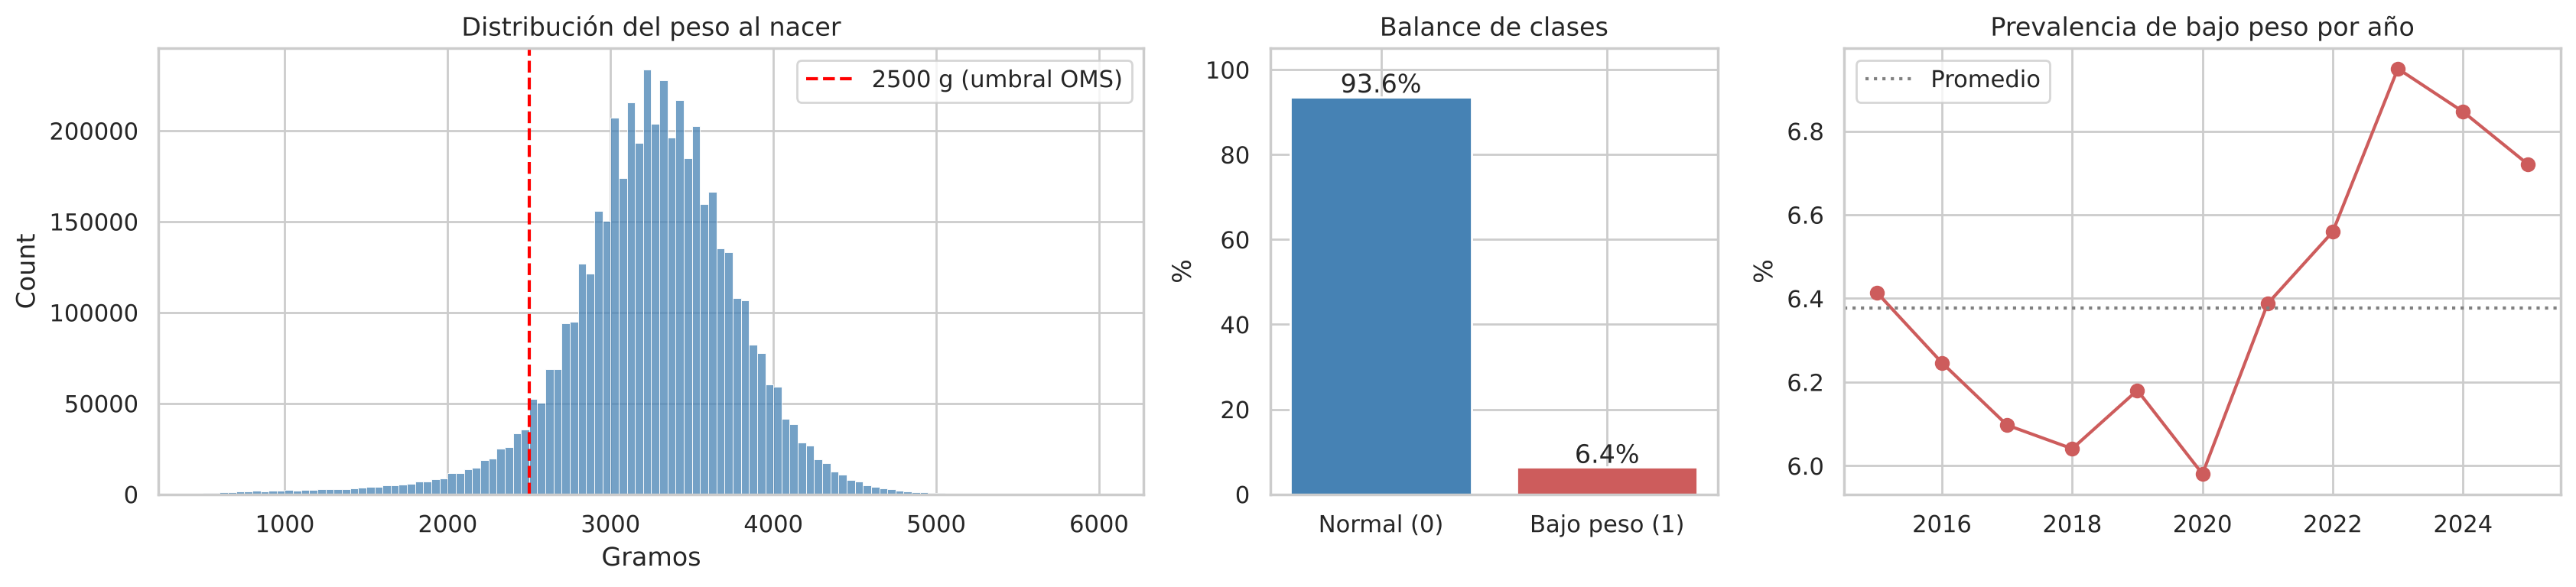

Prevalencia global de bajo peso: 6.38%  |  Ratio de desbalance ≈ 1:15


count   4,871,486.000
mean        3,249.900
std           523.400
min           500.000
25%         2,970.000
50%         3,274.000
75%         3,580.000
max         6,000.000

Prevalencia por año (%):
anio
2015   6.410
2016   6.250
2017   6.100
2018   6.040
2019   6.180
2020   5.980
2021   6.390
2022   6.560
2023   6.950
2024   6.850
2025   6.720


In [17]:
prev = df_eda["bajo_peso"].mean()
fig, axes = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw={"width_ratios": [2.2, 1, 1.6]})

sns.histplot(df_eda["PESO_NACIDO"].dropna(), binwidth=50, ax=axes[0], color="steelblue")
axes[0].axvline(2500, color="red", ls="--", label="2500 g (umbral OMS)")
axes[0].set_title("Distribución del peso al nacer"); axes[0].set_xlabel("Gramos"); axes[0].legend()

vc = df_eda["bajo_peso"].value_counts(normalize=True).sort_index() * 100
axes[1].bar(["Normal (0)", "Bajo peso (1)"], vc.values, color=["steelblue", "indianred"])
for i, v in enumerate(vc.values):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")
axes[1].set_title("Balance de clases"); axes[1].set_ylabel("%"); axes[1].set_ylim(0, 105)

tend = df_eda.groupby("anio")["bajo_peso"].mean() * 100
axes[2].plot(tend.index, tend.values, marker="o", color="indianred")
axes[2].axhline(prev * 100, color="gray", ls=":", label="Promedio")
axes[2].set_title("Prevalencia de bajo peso por año"); axes[2].set_ylabel("%"); axes[2].legend()
guardar("target")

print(f"Prevalencia global de bajo peso: {prev*100:.2f}%  |  Ratio de desbalance ≈ 1:{(1-prev)/prev:.0f}")
print(df_eda["PESO_NACIDO"].describe().round(1).to_string())
print("\nPrevalencia por año (%):"); print(tend.round(2).to_string())

In [18]:
# Redondeo de dígitos (heaping): ¿el peso se registra redondeado?
p = df_eda["PESO_NACIDO"].dropna()
print(f"Pesos múltiplos de 100 g: {(p % 100 == 0).mean()*100:.1f}%  (sin redondeo se esperaría ~1%)")
print(f"Pesos múltiplos de 50 g:  {(p % 50 == 0).mean()*100:.1f}%  (sin redondeo se esperaría ~2%)")
print("\nFrecuencia de valores alrededor del umbral:")
print(p.value_counts().reindex([2450, 2480, 2490, 2495, 2500, 2505, 2510, 2520, 2550]).to_string())

Pesos múltiplos de 100 g: 15.7%  (sin redondeo se esperaría ~1%)
Pesos múltiplos de 50 g:  24.7%  (sin redondeo se esperaría ~2%)

Frecuencia de valores alrededor del umbral:


PESO_NACIDO
2450     6161
2480     5223
2490     4679
2495     1328
2500    16353
2505     1515
2510     5657
2520     6256
2550     8937


In [19]:
# Evidencia para la partición temporal: la relación duración-target es estable por año; la prevalencia no.
d_t = df_eda[["anio", "bajo_peso", "DUR_EMB_PARTO"]].dropna()
score_dur = d_t.groupby("DUR_EMB_PARTO")["bajo_peso"].transform("mean")
por_anio = pd.DataFrame({
    "prevalencia_%": d_t.groupby("anio")["bajo_peso"].mean() * 100,
    "pretermino_%": d_t.assign(pre=d_t["DUR_EMB_PARTO"] < 37).groupby("anio")["pre"].mean() * 100,
    "AUC_DUR_EMB_PARTO": {a: roc_auc_score(g["bajo_peso"], score_dur[g.index]) for a, g in d_t.groupby("anio")}})
display(por_anio.round(3))
pre_tr = df_eda["anio"] <= 2023
print(f"Prevalencia 2015–2023: {df_eda.loc[pre_tr, 'bajo_peso'].mean()*100:.2f}%  |  2024–2025: {df_eda.loc[~pre_tr, 'bajo_peso'].mean()*100:.2f}%")

,prevalencia_%,pretermino_%,AUC_DUR_EMB_PARTO
2015,6.414,6.474,0.884
2016,6.246,6.625,0.887
2017,6.097,6.499,0.889
2018,6.041,6.652,0.891
2019,6.181,6.832,0.891
2020,5.981,6.387,0.884
2021,6.387,6.847,0.888
2022,6.559,6.940,0.884
2023,6.949,7.469,0.885
2024,6.846,7.662,0.888


Prevalencia 2015–2023: 6.30%  |  2024–2025: 6.79%


**Interpretación.**
- **Distribución:** el peso tiene media de 3250 g y desviación estándar de 523 g, con una cola izquierda larga. La sección 9 muestra que esa cola corresponde principalmente a los partos prematuros.
- **Desbalance:** la prevalencia de bajo peso es **6.38%**, una proporción de 1:15. Un modelo que prediga siempre "peso normal" tendría 93.6% de accuracy sin detectar un solo caso.

  **Decisión:** partición estratificada por `bajo_peso` entre entrenamiento y validación, ponderación de clases o técnicas de balanceo, y evaluación con recall, F1, AUC-ROC y AUC-PR.
- **Tendencia temporal:** la prevalencia bajó de 6.4% (2015) a 6.0% (2020) y luego subió a 6.9% (2023): 6.30% en 2015–2023 y 6.79% en 2024–2025. Detrás hay un aumento de la proporción de partos pretérmino, de 6.4% (2020) a 7.7% (2024 y 2025). En cambio, el AUC de `DUR_EMB_PARTO` es estable por año (0.884–0.891), así que no hay evidencia de que la relación entre la variable y el target se rompa; lo que cambia es la prevalencia, y un split aleatorio no la ve.

  **Decisión:** **partición temporal.** Entrenamiento y validación con 2015–2023 (80% / 20% al azar, estratificado) y prueba con 2024–2025, que se usa una sola vez al final. El test simula el uso real: entrenar con el pasado y predecir el futuro. Cuidados: 2025 llega hasta el 30/11/2025 (sin diciembre), lo que da un leve sesgo estacional; la precisión y el F1 cambian de nivel porque la prevalencia del test es mayor, así que los modelos se comparan con AUC-ROC, AUC-PR y recall a precisión fija, y el umbral de decisión se calibra en validación, no en test. El preprocesador se ajusta solo con entrenamiento. El split aleatorio 80/20 queda como referencia secundaria.
- **Redondeo de dígitos (heaping):** el 15.7% de los pesos son múltiplos de 100 g, frente al ~1% esperable. Hay 16 353 registros con exactamente 2500 g, frente a 4679 con 2490 g. **Hipótesis (no verificable con estos datos):** parte de los recién nacidos que pesaron un poco menos de 2500 g se registró como 2500 g y quedó clasificada como peso normal. Si fuera así, habría ruido en la etiqueta justo en el umbral.

  **Decisión:** se mantiene el umbral estándar de la OMS (< 2500 g) y el redondeo se reporta como limitación.


## 6. Análisis univariado de las features

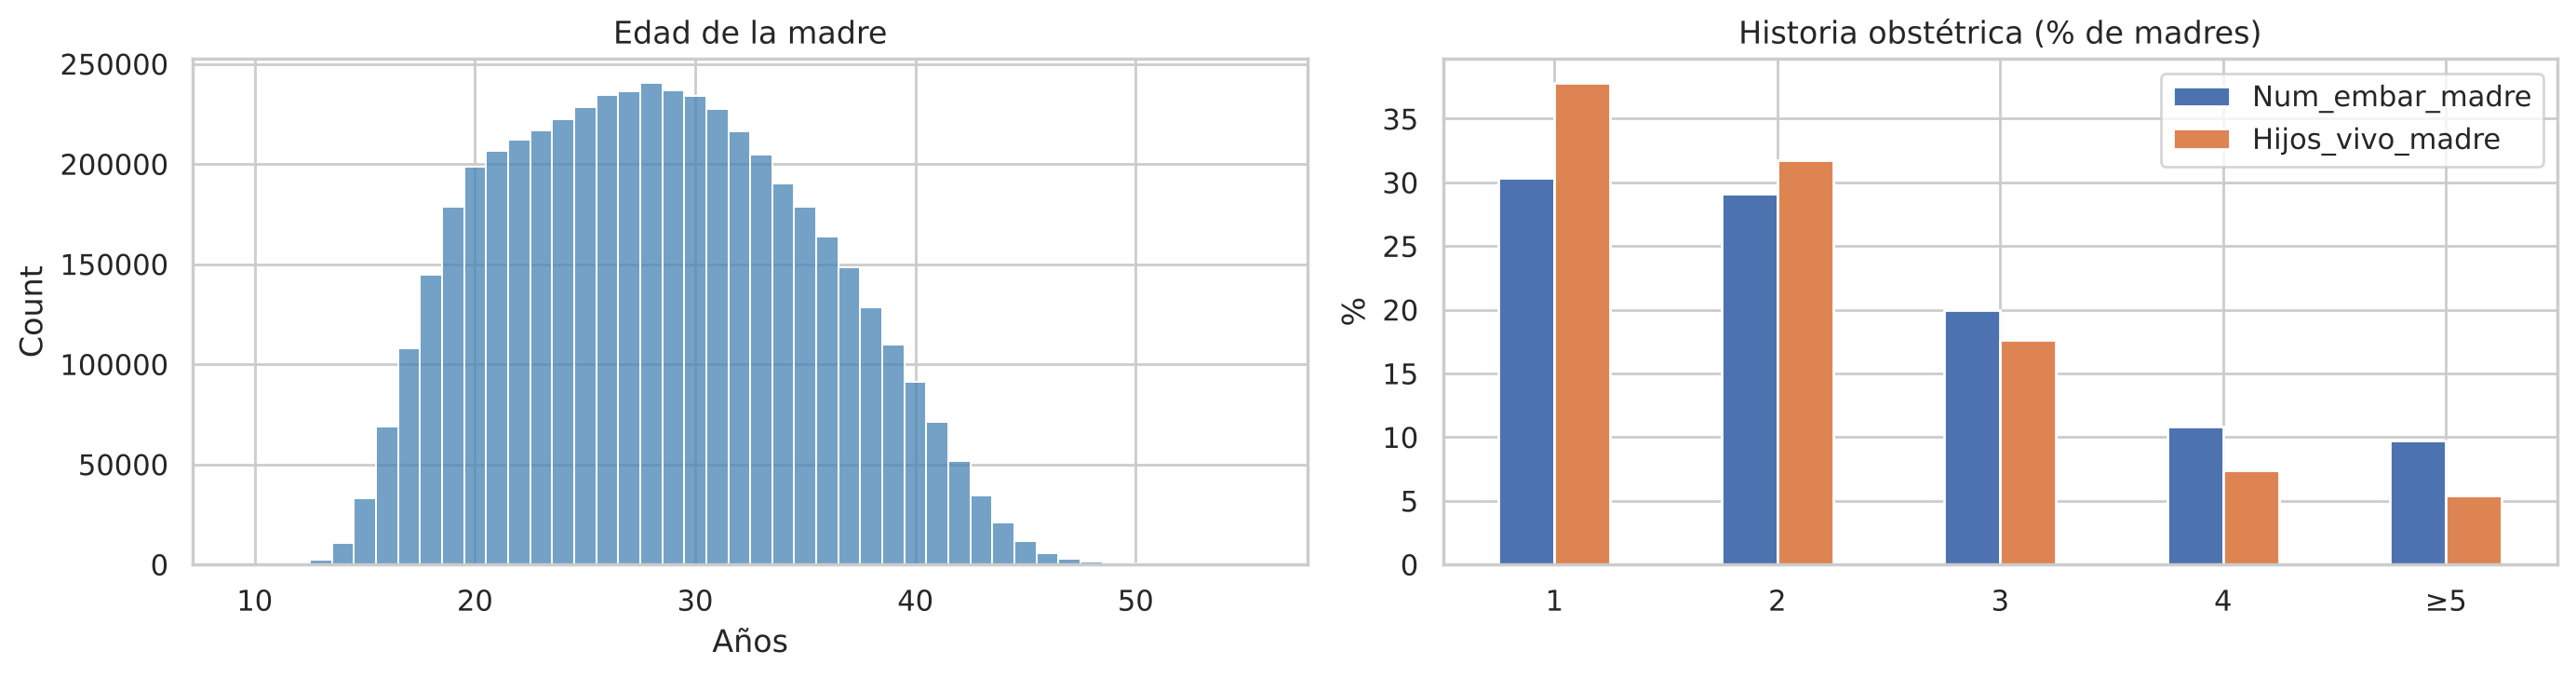

count   4,874,408.000
mean           28.300
std             6.900
min            10.000
25%            23.000
50%            28.000
75%            33.000
max            55.000
Madres ≤17 años: 4.6%  |  ≥35 años: 21.0%


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
sns.histplot(df_eda["Edad_Madre"].dropna(), discrete=True, ax=axes[0], color="steelblue")
axes[0].set_title("Edad de la madre"); axes[0].set_xlabel("Años")

paridad = ["Num_embar_madre", "Hijos_vivo_madre"]   # Hijos_vivo_madre se muestra solo como evidencia de redundancia (sección 8)
dist_par = pd.DataFrame({c: df_eda[c].clip(upper=5).value_counts(normalize=True).sort_index() * 100 for c in paridad})
dist_par.index = [f"{int(i)}" if i < 5 else "≥5" for i in dist_par.index]
dist_par.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Historia obstétrica (% de madres)"); axes[1].set_ylabel("%")
guardar("univariado_numericas")

print(df_eda["Edad_Madre"].describe().round(1).to_string())
print(f"Madres ≤17 años: {(df_eda['Edad_Madre'] <= 17).mean()*100:.1f}%  |  ≥35 años: {(df_eda['Edad_Madre'] >= 35).mean()*100:.1f}%")

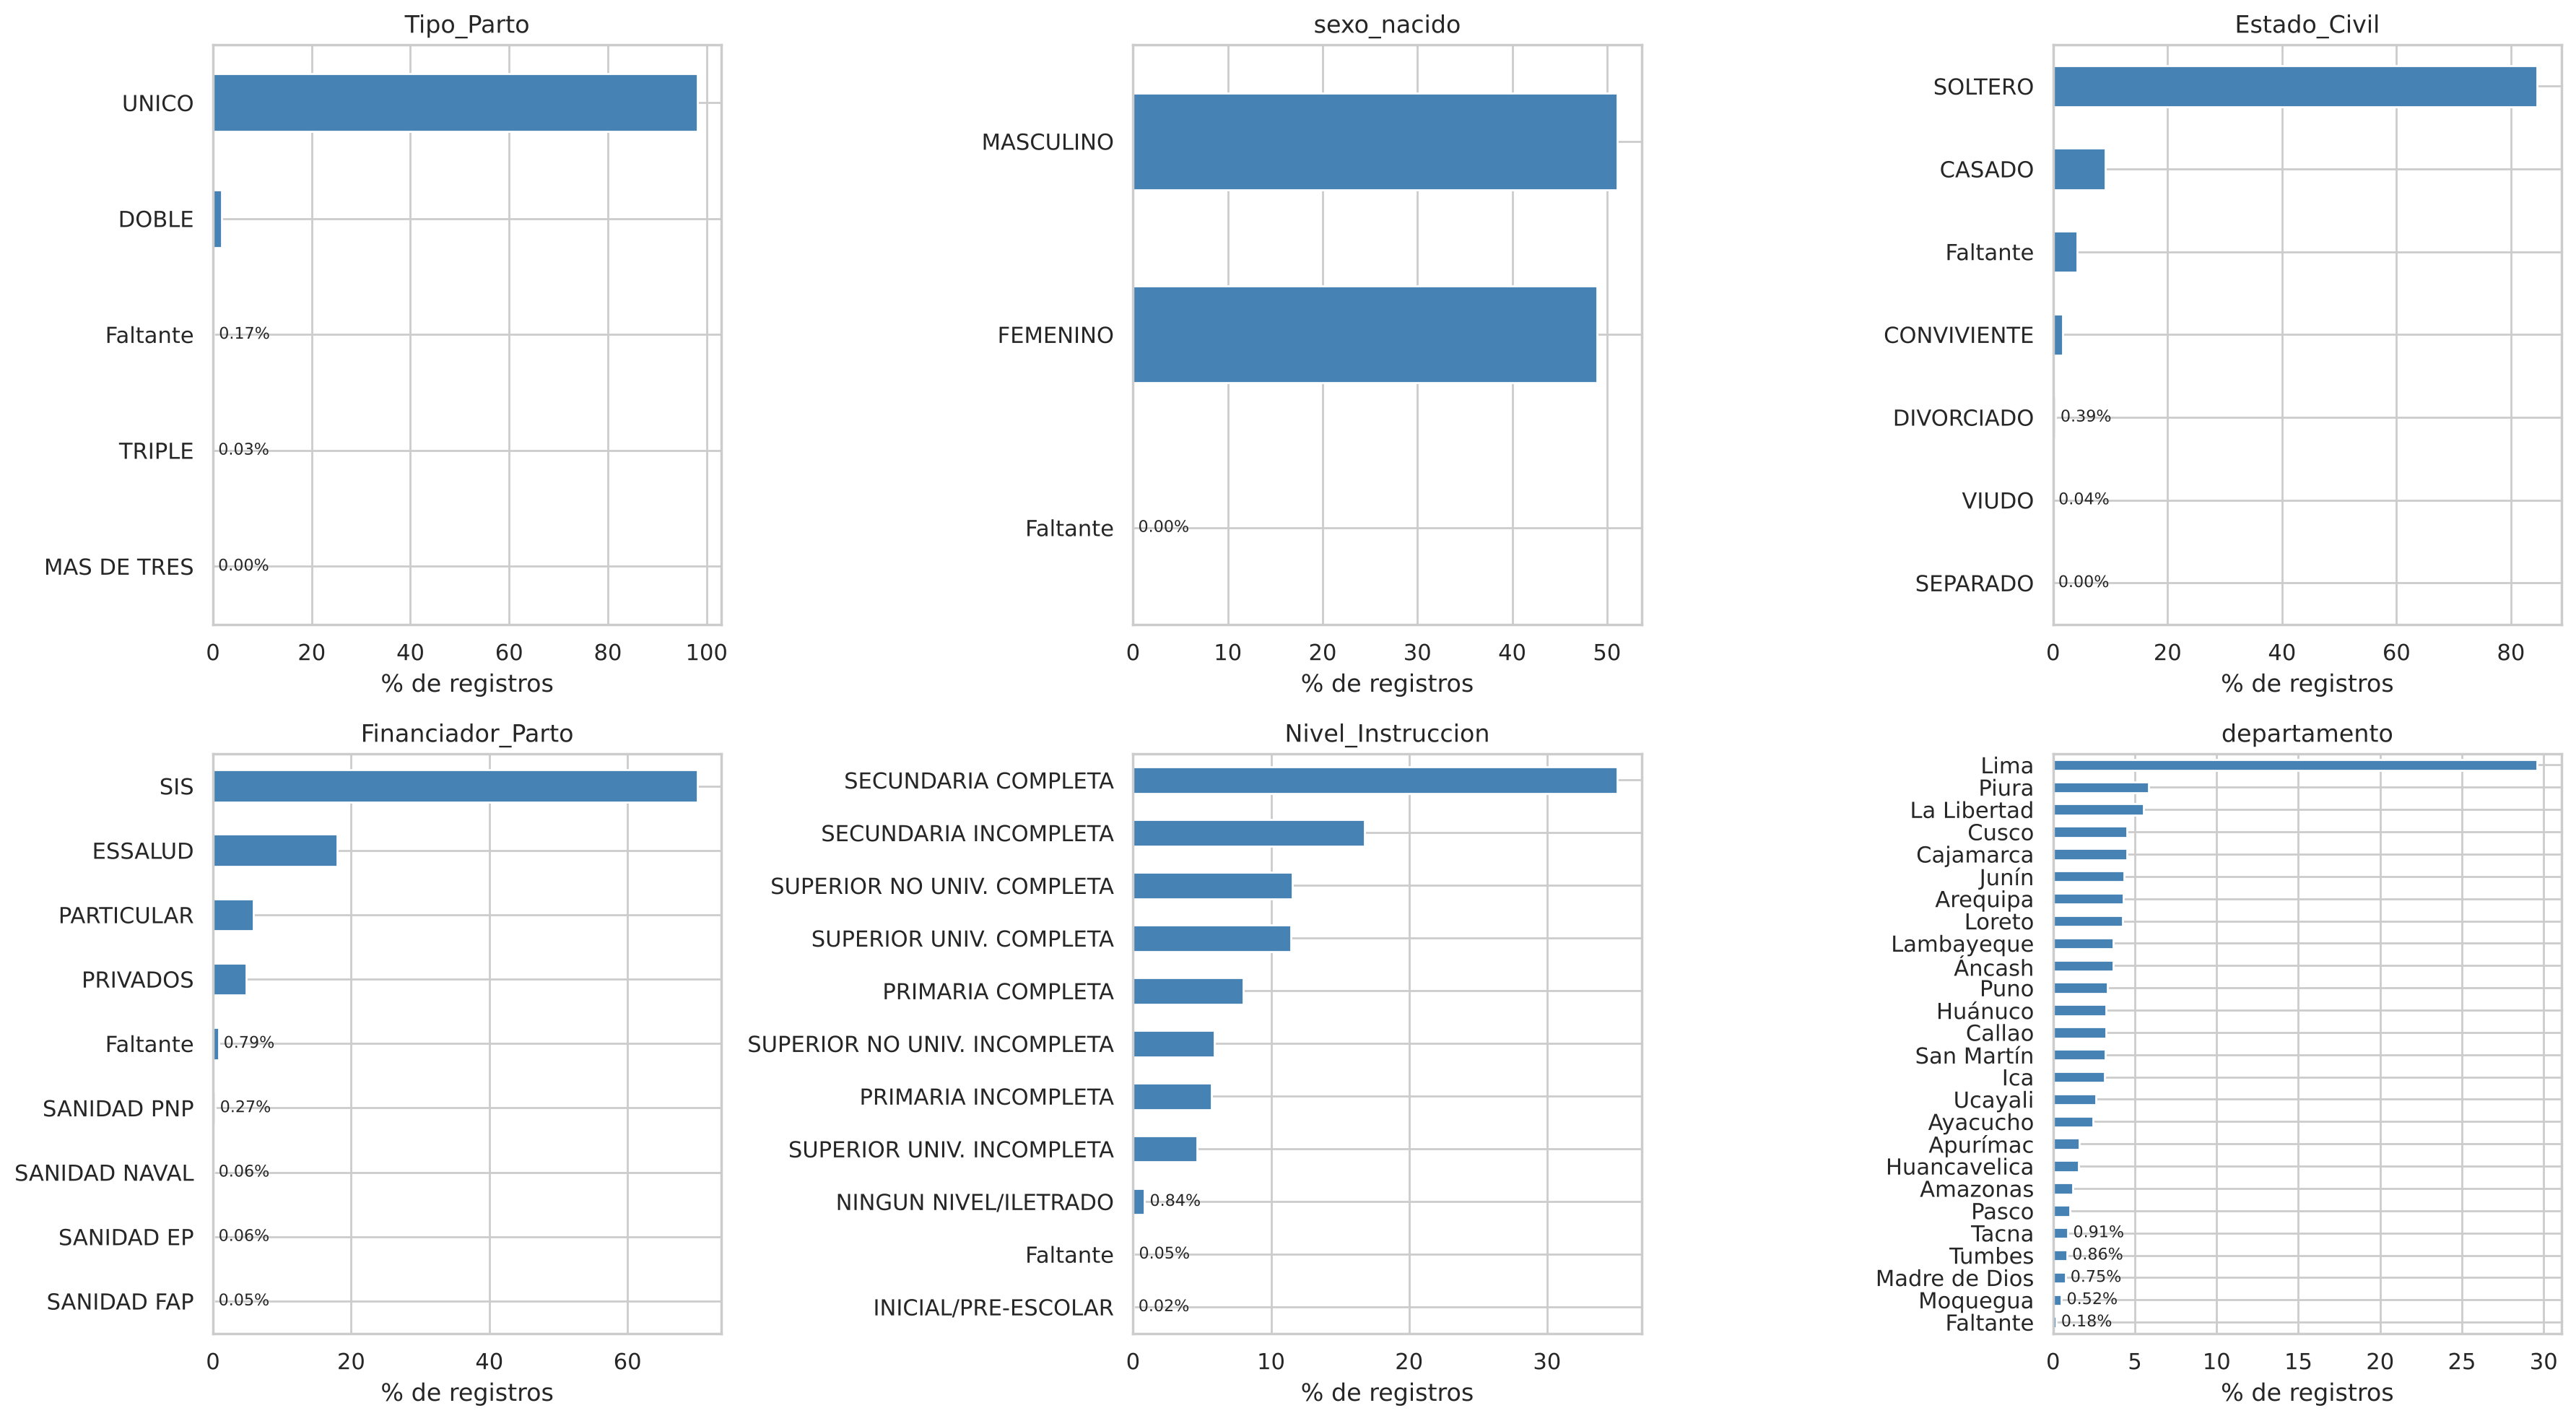

In [21]:
cat_cols = ["Tipo_Parto", "sexo_nacido", "Estado_Civil", "Financiador_Parto", "Nivel_Instruccion", "departamento"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, c in zip(axes.flat, cat_cols):
    vc = df_eda[c].value_counts(normalize=True, dropna=False).sort_values() * 100
    vc.index = ["Faltante" if pd.isna(i) else str(i) for i in vc.index]
    vc.plot.barh(ax=ax, color="steelblue")
    ax.set_title(c); ax.set_xlabel("% de registros")
    for i, v in enumerate(vc.values):
        if v < 1:
            ax.text(v, i, f" {v:.2f}%", va="center", fontsize=8)
guardar("univariado_categoricas")

In [22]:
for c in cat_cols + ["pais_grupo"]:
    vc = df_eda[c].value_counts(dropna=False)
    t = pd.DataFrame({"n": vc, "pct": vc / len(df_eda) * 100})
    t.index = ["Faltante" if pd.isna(i) else str(i) for i in t.index]
    print(f"\n{c}:"); print(t.round(2).to_string())


Tipo_Parto:
                   n    pct
UNICO        4781890 98.100
DOBLE          82682  1.700
Faltante        8374  0.170
TRIPLE          1486  0.030
MAS DE TRES       78  0.000

sexo_nacido:
                 n    pct
MASCULINO  2490143 51.080
FEMENINO   2384174 48.910
Faltante       193  0.000

Estado_Civil:
                   n    pct
SOLTERO      4124661 84.620
CASADO        445017  9.130
Faltante      202327  4.150
CONVIVIENTE    81154  1.660
DIVORCIADO     19164  0.390
VIUDO           2114  0.040
SEPARADO          73  0.000

Financiador_Parto:
                     n    pct
SIS            3416656 70.090
ESSALUD         876584 17.980
PARTICULAR      284196  5.830
PRIVADOS        236672  4.860
Faltante         38679  0.790
SANIDAD PNP      13329  0.270
SANIDAD NAVAL     3108  0.060
SANIDAD EP        2682  0.060
SANIDAD FAP       2604  0.050

Nivel_Instruccion:
                                    n    pct
SECUNDARIA COMPLETA           1710409 35.090
SECUNDARIA INCOMPLETA          8

**Interpretación** (los números salen de la tabla de conteos de la celda anterior):
- **Edad materna:** la media es 28.3 años. El 4.6% de las madres tiene 17 años o menos y el 21% tiene 35 o más.
- **Historia obstétrica:** la mayoría de madres está en su primer o segundo embarazo. `Hijos_vivo_madre` se muestra solo como evidencia de su redundancia con `Num_embar_madre` (sección 8).
- **Categorías raras que hay que agrupar:**
  - `Tipo_Parto`: "TRIPLE" (1486) y "MAS DE TRES" (78) se unen con "DOBLE" (82 682) en "MÚLTIPLE".
  - `Financiador_Parto`: las cuatro sanidades (entre 2604 y 13 329 registros cada una) se agrupan en "SANIDAD FF.AA./PNP".
  - `Nivel_Instruccion`: "INICIAL/PRE-ESCOLAR" (871) se une con "NINGÚN NIVEL/ILETRADO" (40 957).
  - `pais_grupo`: Venezuela representa el 2.1% y el resto de países el 0.4%.
- **Concentración:** el SIS financia el 70.1% de los partos y Lima concentra el 29.6% de los registros. El modelo verá muchos más ejemplos de estos grupos que del resto.


## 7. Análisis bivariado: features vs bajo peso

Para cada feature se calcula la **tasa de bajo peso por categoría**. La línea roja marca la prevalencia global; cuanto más se alejan las barras de esa línea, más información aporta la variable. Se omiten las categorías con menos de 300 registros para que no distorsionen la escala.

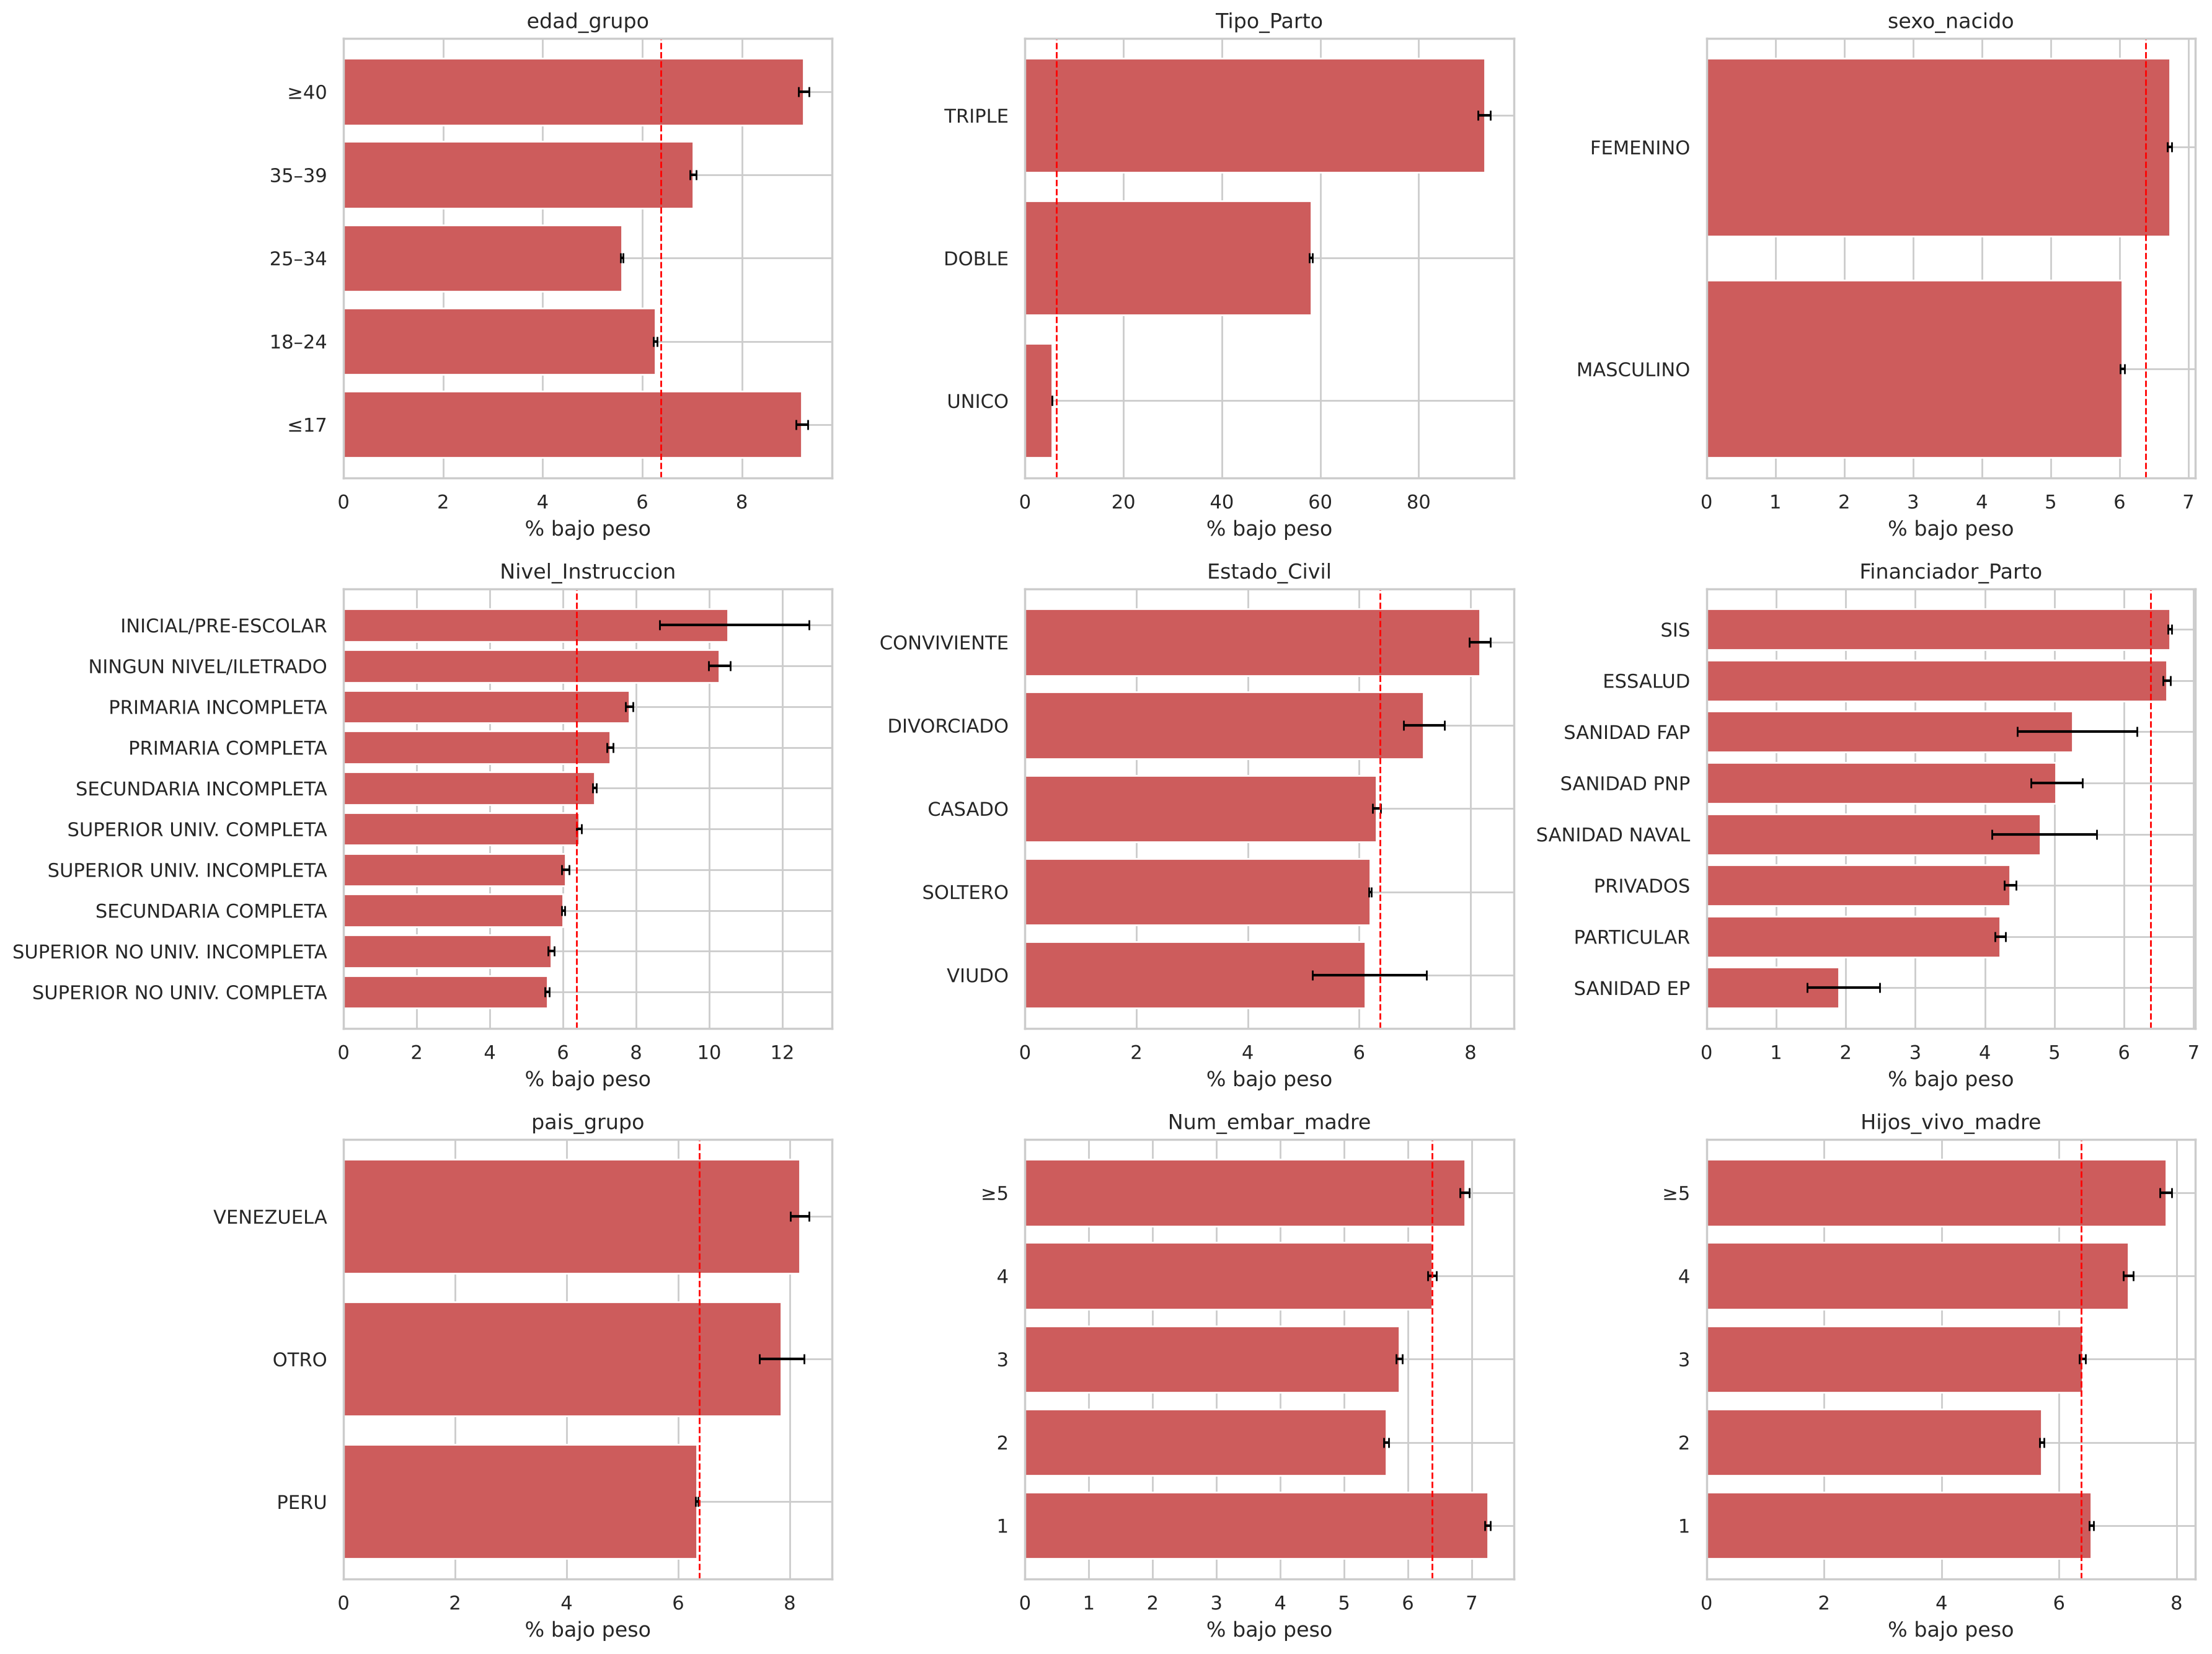


edad_grupo:
            tasa  ic_inf  ic_sup        n
edad_grupo                               
≤17        9.200   9.080   9.320   223510
18–24      6.260   6.220   6.300  1379065
25–34      5.590   5.560   5.620  2247879
35–39      7.020   6.960   7.080   728608
≥40        9.240   9.140   9.350   292328

Tipo_Parto:
             tasa  ic_inf  ic_sup        n
Tipo_Parto                                
DOBLE      58.130  57.790  58.470    82620
TRIPLE     93.440  92.060  94.590     1479
UNICO       5.460   5.440   5.480  4778954

sexo_nacido:
             tasa  ic_inf  ic_sup        n
sexo_nacido                               
FEMENINO    6.730   6.700   6.760  2382685
MASCULINO   6.040   6.010   6.070  2488611

Nivel_Instruccion:
                               tasa  ic_inf  ic_sup        n
Nivel_Instruccion                                           
INICIAL/PRE-ESCOLAR          10.510   8.640  12.730      866
NINGUN NIVEL/ILETRADO        10.270   9.980  10.570    40877
PRIMARIA COMPLE

In [23]:
df_eda["edad_grupo"] = pd.cut(df_eda["Edad_Madre"], [9, 17, 24, 34, 39, 55],
                              labels=["≤17", "18–24", "25–34", "35–39", "≥40"])
for c in paridad:
    df_eda[c + "_cat"] = pd.Categorical(
        df_eda[c].clip(upper=5).map(lambda v: np.nan if pd.isna(v) else ("≥5" if v >= 5 else str(int(v)))),
        categories=["0", "1", "2", "3", "4", "≥5"], ordered=True)

def tasa(col, min_n=300, z=1.96):
    """Tasa de bajo peso por categoría con intervalo de confianza de Wilson al 95%."""
    t = df_eda.groupby(col, observed=True)["bajo_peso"].agg(p="mean", n="count")
    t = t[t["n"] >= min_n].copy()
    centro = (t["p"] + z**2 / (2 * t["n"])) / (1 + z**2 / t["n"])
    margen = z * np.sqrt(t["p"] * (1 - t["p"]) / t["n"] + z**2 / (4 * t["n"]**2)) / (1 + z**2 / t["n"])
    t["tasa"], t["ic_inf"], t["ic_sup"] = t["p"] * 100, (centro - margen) * 100, (centro + margen) * 100
    return t[["tasa", "ic_inf", "ic_sup", "n"]]

ordenadas = {"edad_grupo"} | {c + "_cat" for c in paridad}
bivar = ["edad_grupo", "Tipo_Parto", "sexo_nacido", "Nivel_Instruccion", "Estado_Civil", "Financiador_Parto",
         "pais_grupo", "Num_embar_madre_cat", "Hijos_vivo_madre_cat"]   # Estado_Civil e Hijos_vivo_madre: solo como evidencia
fig, axes = plt.subplots(3, 3, figsize=(18, 13.5))
tablas = {}
for ax, c in zip(axes.flat, bivar):
    t = tasa(c); tablas[c] = t
    tt = t if c in ordenadas else t.sort_values("tasa")
    err = np.vstack([tt["tasa"] - tt["ic_inf"], tt["ic_sup"] - tt["tasa"]])
    ax.barh(tt.index.astype(str), tt["tasa"], xerr=err, color="indianred", ecolor="black", capsize=3)
    ax.axvline(prev * 100, color="red", ls="--", lw=1)
    ax.set_title(c.replace("_cat", "")); ax.set_xlabel("% bajo peso"); ax.set_ylabel("")
for ax in axes.flat[len(bivar):]:
    ax.axis("off")
guardar("bivariado_tasas")

for c, t in tablas.items():
    print(f"\n{c.replace('_cat', '')}:"); print(t.round(2).to_string())

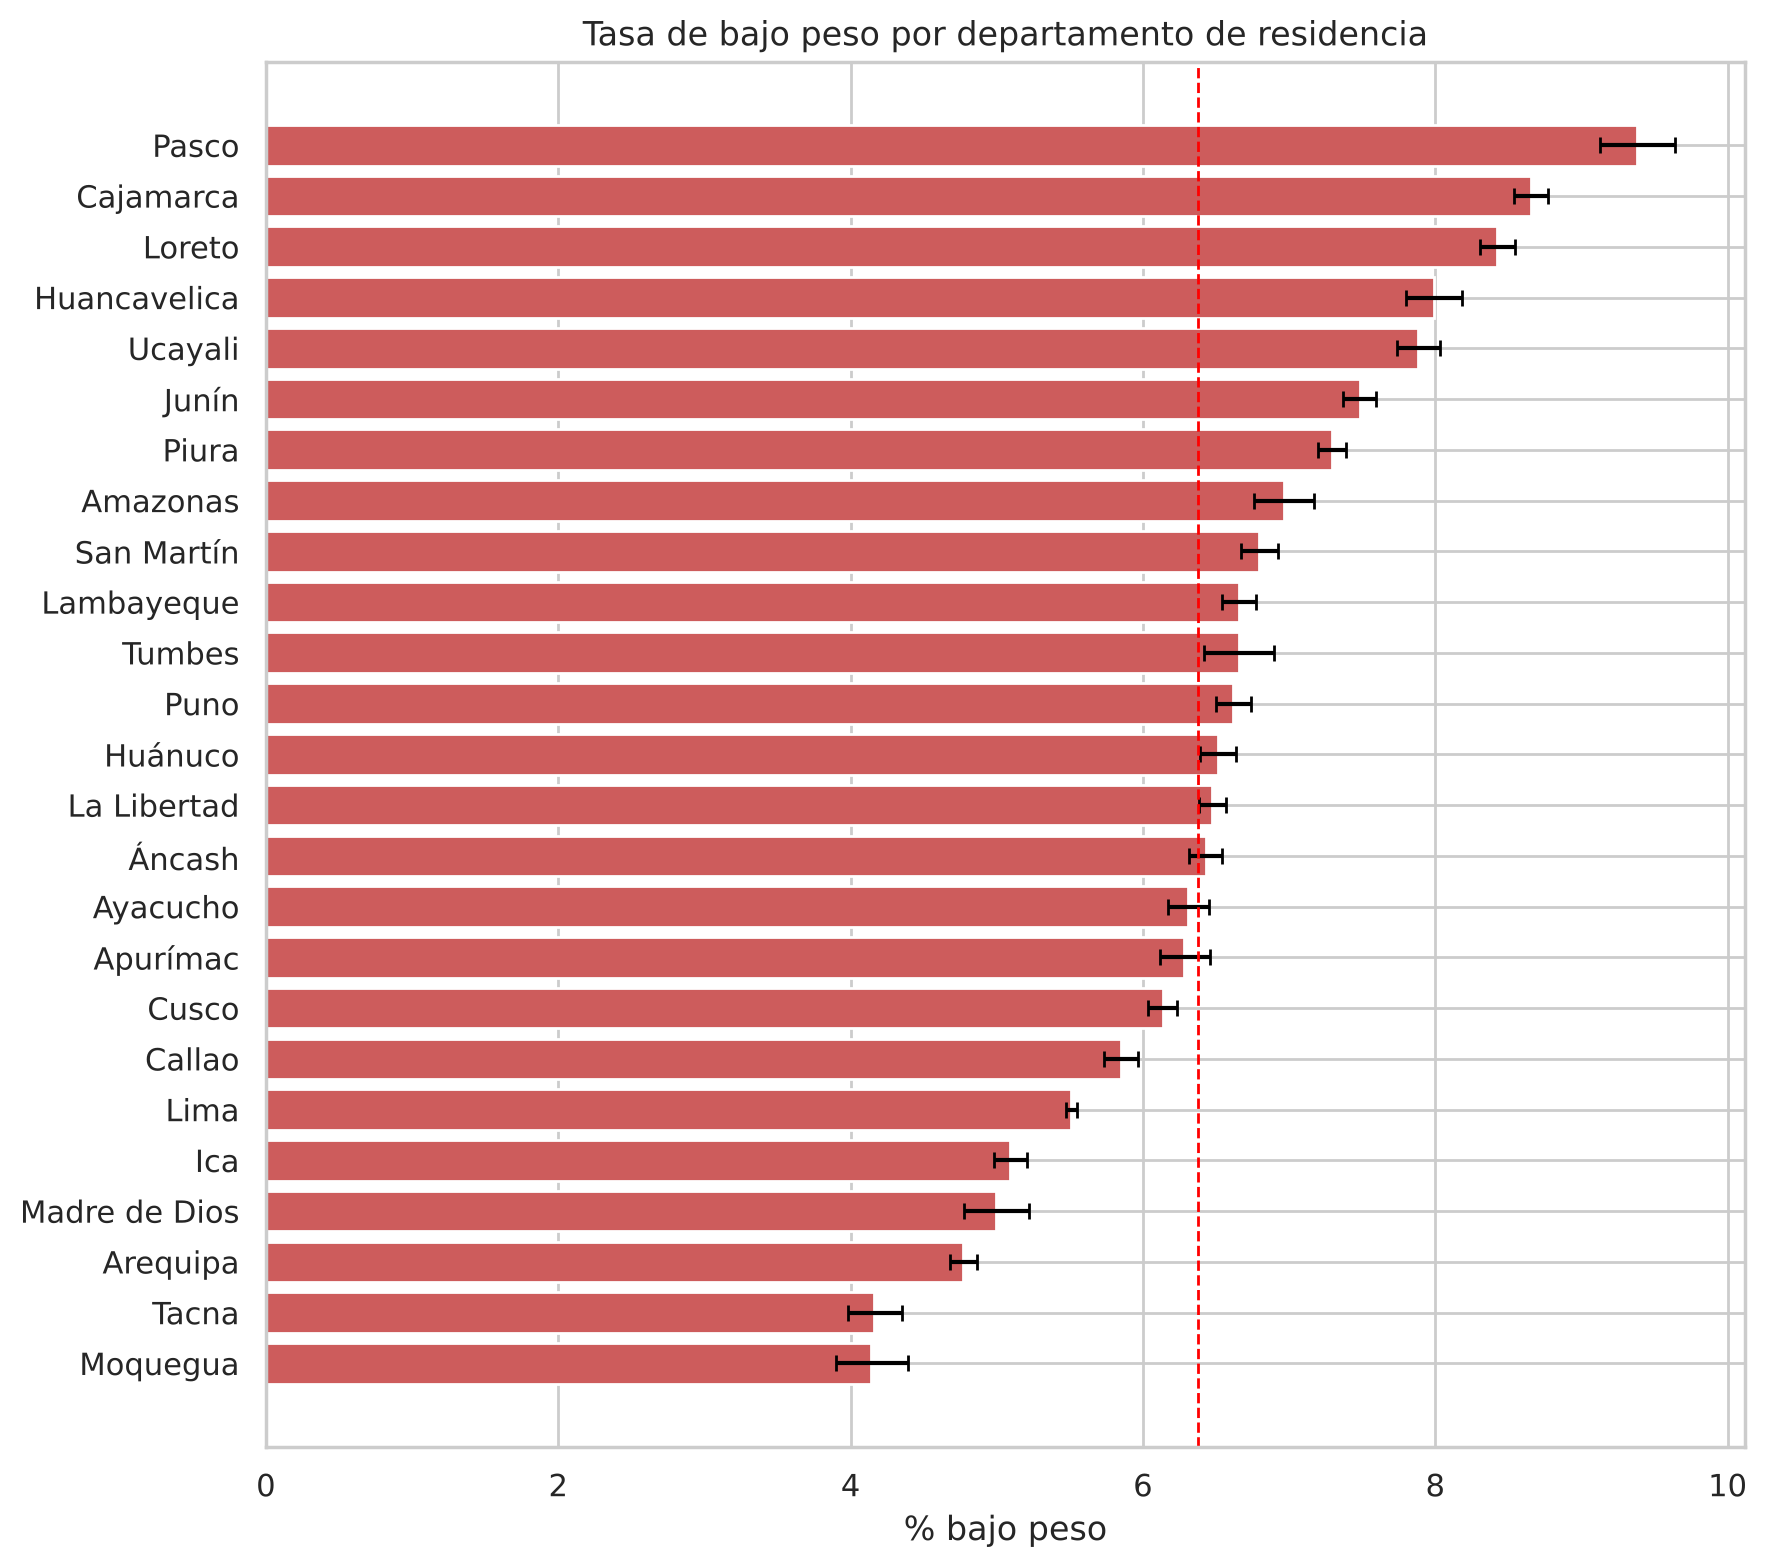

               tasa  ic_inf  ic_sup        n
departamento                                
Pasco         9.380   9.130   9.640    50102
Cajamarca     8.650   8.540   8.770   219435
Loreto        8.430   8.310   8.550   207853
Huancavelica  7.990   7.800   8.180    75257
Ucayali       7.880   7.740   8.030   126380
Junín         7.480   7.370   7.600   210751
Piura         7.290   7.200   7.390   284082
Amazonas      6.960   6.760   7.170    59240
San Martín    6.800   6.670   6.920   156143
Lambayeque    6.660   6.540   6.770   178323
Tumbes        6.650   6.420   6.900    41673
Puno          6.620   6.500   6.740   161008
Huánuco       6.510   6.390   6.640   157502
La Libertad   6.470   6.380   6.570   268675
Áncash        6.430   6.320   6.540   178022
Ayacucho      6.310   6.170   6.450   119057
Apurímac      6.280   6.120   6.460    78226
Cusco         6.140   6.040   6.240   221022
Callao        5.850   5.730   5.970   157087
Lima          5.510   5.470   5.550  1442926
Ica       

In [24]:
t_dep = tasa("departamento").sort_values("tasa")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(t_dep.index.astype(str), t_dep["tasa"], color="indianred", ecolor="black", capsize=3,
        xerr=np.vstack([t_dep["tasa"] - t_dep["ic_inf"], t_dep["ic_sup"] - t_dep["tasa"]]))
ax.axvline(prev * 100, color="red", ls="--", lw=1)
ax.set_title("Tasa de bajo peso por departamento de residencia"); ax.set_xlabel("% bajo peso"); ax.set_ylabel("")
guardar("bivariado_departamento")
tablas["departamento"] = t_dep
print(t_dep.sort_values("tasa", ascending=False).round(2).to_string())

In [25]:
# Resumen: brecha entre la categoría de mayor y menor riesgo de cada feature.
# Se agrupan las categorías raras decididas en la sección 6 y se exige un mínimo de 5000 registros por categoría,
# para que una categoría pequeña no domine la comparación (con min_n=300, una sanidad de 2681 registros daba un riesgo relativo de 3.5).
GRUPOS = {
    "Tipo_Parto": {"DOBLE": "MÚLTIPLE", "TRIPLE": "MÚLTIPLE", "MAS DE TRES": "MÚLTIPLE"},
    "Financiador_Parto": {k: "SANIDAD FF.AA./PNP" for k in ["SANIDAD EP", "SANIDAD FAP", "SANIDAD NAVAL", "SANIDAD PNP"]},
    "Nivel_Instruccion": {"INICIAL/PRE-ESCOLAR": "NINGÚN NIVEL O INICIAL", "NINGUN NIVEL/ILETRADO": "NINGÚN NIVEL O INICIAL"},
}
for c, m in GRUPOS.items():
    df_eda[c + "_grp"] = df_eda[c].astype(object).replace(m).astype("category")

en_modelo = {"Estado_Civil": "No", "Hijos_vivo_madre_cat": "No"}
tablas_g = {c: tasa(c + "_grp" if c in GRUPOS else c, min_n=5000) for c in bivar + ["departamento"]}
brecha = pd.DataFrame({
    c.replace("_cat", ""): {"tasa_min_%": t["tasa"].min(), "tasa_max_%": t["tasa"].max(),
                            "categoria_max": t["tasa"].idxmax(), "n_categoria_max": int(t.loc[t["tasa"].idxmax(), "n"]),
                            "brecha_pp": t["tasa"].max() - t["tasa"].min(),
                            "riesgo_relativo": t["tasa"].max() / t["tasa"].min(),
                            "en_modelo": en_modelo.get(c, "Sí")}
    for c, t in tablas_g.items()}).T.sort_values("brecha_pp", ascending=False)
brecha


,tasa_min_%,tasa_max_%,categoria_max,n_categoria_max,brecha_pp,riesgo_relativo,en_modelo
Tipo_Parto,5.458,58.742,MÚLTIPLE,84177,53.284,10.763,Sí
departamento,4.138,9.379,Pasco,50102,5.241,2.266,Sí
Nivel_Instruccion,5.568,10.280,NINGÚN NIVEL O INICIAL,41743,4.712,1.846,Sí
edad_grupo,5.588,9.242,≥40,292328,3.654,1.654,Sí
Financiador_Parto,4.221,6.662,SIS,3414854,2.441,1.578,Sí
Hijos_vivo_madre,5.704,7.819,≥5,263015,2.115,1.371,No
Estado_Civil,6.201,8.168,CONVIVIENTE,81095,1.967,1.317,No
pais_grupo,6.334,8.174,VENEZUELA,101550,1.840,1.291,Sí
Num_embar_madre,5.657,7.252,1,1463442,1.595,1.282,Sí
sexo_nacido,6.041,6.729,FEMENINO,2382685,0.689,1.114,Sí


In [26]:
# Evidencia para interpretar el gradiente educativo: edad media de la madre por nivel de instrucción
print(df_eda.groupby("Nivel_Instruccion", observed=True)["Edad_Madre"].agg(["mean", "median"]).round(1).to_string())

                               mean  median
Nivel_Instruccion                          
INICIAL/PRE-ESCOLAR          31.200  32.000
NINGUN NIVEL/ILETRADO        33.700  35.000
PRIMARIA COMPLETA            29.200  29.000
PRIMARIA INCOMPLETA          30.700  31.000
SECUNDARIA COMPLETA          27.500  27.000
SECUNDARIA INCOMPLETA        25.000  24.000
SUPERIOR NO UNIV. COMPLETA   30.400  30.000
SUPERIOR NO UNIV. INCOMPLETA 26.900  26.000
SUPERIOR UNIV. COMPLETA      32.500  32.000
SUPERIOR UNIV. INCOMPLETA    26.700  26.000


**Interpretación.** Todas las tasas incluyen su intervalo de confianza del 95%. Con millones de registros casi cualquier diferencia es estadísticamente significativa, así que lo relevante es el tamaño de la brecha. Los intervalos sí importan en categorías pequeñas, como las sanidades o "INICIAL/PRE-ESCOLAR". Estas tasas son **marginales**: no controlan por la duración del embarazo, y la sección 7.2 evalúa si cada variable conserva su efecto al hacerlo.
- **Tipo de parto:** es el factor más fuerte por amplio margen. El bajo peso llega a 58.1% en partos dobles y 93.4% en triples, frente a 5.5% en partos únicos. Sin embargo, los partos múltiples son solo el 1.7% del total (sección 6), así que esta variable ayuda a detectar un subgrupo pequeño pero no resuelve el resto.
- **Departamento:** la tasa va de 4.1% (Moquegua, Tacna) a 9.4% (Pasco). La hipótesis de que el departamento refleja la altitud **no se puede verificar con este dataset**, porque no tiene una variable de altitud. Solo puede decirse que el departamento captura diferencias geográficas que el modelo puede aprovechar; para atribuirlas a la altitud habría que cruzar los datos con una fuente externa.
- **Nivel de instrucción:** hay un gradiente de 10.3% en madres sin nivel educativo a ~5.6% en superior no universitaria. La educación universitaria completa (6.4%) rompe el patrón. La celda anterior muestra que esas madres son de las de mayor edad (32.5 años de media, frente a 30.4 en superior no universitaria completa). Esto es consistente con que la edad influya, pero no lo demuestra: el análisis es bivariado.
- **Financiador:** SIS y EsSalud tienen ~6.6%, mientras que los partos particulares y privados tienen ~4.3%. La sanidad del Ejército muestra 1.9%, pero con un intervalo amplio (1.5–2.5%) por tener solo 2681 registros; por eso las cuatro sanidades se agrupan y la tabla de brechas exige al menos 5000 registros por categoría.
- **País de origen:** las madres venezolanas tienen 8.2% (IC 8.0–8.3%) frente a 6.3% de las peruanas. La diferencia es clara, pero afecta a un grupo pequeño.

  **Decisión:** `pais_grupo` se mantiene como feature por decisión del equipo (criterio 6). Se interpreta como un marcador de contexto, no como un efecto de la nacionalidad.
- **Edad materna:** la relación tiene **forma de U**: 9.2% en madres de 17 años o menos, 5.6% entre 25 y 34, y 9.2% en madres de 40 o más.

  **Decisión:** la edad debe representarse de forma que capture la U, por ejemplo con grupos de edad. Si se usa como variable continua, el modelo elegido debe poder representar relaciones no lineales.
- **Historia obstétrica:** el número de embarazos muestra una U leve: 7.3% en primigestas, 5.7% en el segundo embarazo y 6.9% con cinco o más.
- **Sexo:** el riesgo es algo mayor en mujeres (6.7%) que en varones (6.0%), con intervalos que no se solapan.
- **Estado civil:** "conviviente" muestra la tasa más alta (8.2%), pero por lo visto en la sección 4.6 este resultado no es confiable.

**Brechas entre la categoría de mayor y menor riesgo** (tabla de la celda de resumen, con categorías agrupadas): tipo de parto 53.3 puntos porcentuales, departamento 5.2, nivel de instrucción 4.7, edad 3.7, financiador 2.4, país de origen 1.8, número de embarazos 1.6 y sexo 0.7. `pais_grupo` ocupa el sexto lugar entre las 8 variables del modelo. Las variables excluidas `Hijos_vivo_madre` (2.1) y `Estado_Civil` (2.0) se muestran solo como evidencia.


### 7.1 Features vs peso al nacer (verificación complementaria)

El proyecto es de **clasificación**: el target es `bajo_peso`. Esta subsección usa el peso en gramos solo como verificación complementaria: comprueba si las relaciones observadas con `bajo_peso` se mantienen con el peso continuo, es decir, que no son un efecto del corte en 2500 g.

In [27]:
pesos = {}
for c in [b for b in bivar] + ["departamento"]:
    g_ = df_eda.groupby(c, observed=True)["PESO_NACIDO"].agg(["mean", "count"])
    g_ = g_[g_["count"] >= 300]
    pesos[c.replace("_cat", "")] = {"peso_min_g": g_["mean"].min(), "cat_min": g_["mean"].idxmin(),
                                    "peso_max_g": g_["mean"].max(), "cat_max": g_["mean"].idxmax(),
                                    "brecha_g": g_["mean"].max() - g_["mean"].min()}
brecha_peso = pd.DataFrame(pesos).T.sort_values("brecha_g", ascending=False)
display(brecha_peso)

print("Spearman con PESO_NACIDO:")
print(df_eda[["Edad_Madre"] + paridad + ["PESO_NACIDO"]].corr(method="spearman")["PESO_NACIDO"].drop("PESO_NACIDO").round(3).to_string())
print("\nPeso medio por grupo de edad (g):")
print(df_eda.groupby("edad_grupo", observed=True)["PESO_NACIDO"].mean().round(0).to_string())

,peso_min_g,cat_min,peso_max_g,cat_max,brecha_g
Tipo_Parto,"1,741.177",TRIPLE,"3,266.147",UNICO,"1,524.969"
departamento,"3,086.785",Pasco,"3,482.430",Tacna,395.645
Financiador_Parto,"3,229.802",SIS,"3,455.331",SANIDAD EP,225.529
edad_grupo,"3,069.073",≤17,"3,289.441",25–34,220.368
Nivel_Instruccion,"3,101.150",NINGUN NIVEL/ILETRADO,"3,298.988",SUPERIOR NO UNIV. COMPLETA,197.838
Estado_Civil,"3,185.378",CONVIVIENTE,"3,298.357",CASADO,112.978
Num_embar_madre,"3,180.708",1,"3,291.705",4,110.998
sexo_nacido,"3,199.518",FEMENINO,"3,298.200",MASCULINO,98.682
Hijos_vivo_madre,"3,202.129",1,"3,283.228",3,81.099
pais_grupo,"3,188.099",VENEZUELA,"3,251.375",PERU,63.276


Spearman con PESO_NACIDO:


Edad_Madre         0.096
Num_embar_madre    0.088
Hijos_vivo_madre   0.069

Peso medio por grupo de edad (g):
edad_grupo
≤17     3,069.000
18–24   3,201.000
25–34   3,289.000
35–39   3,283.000
≥40     3,231.000


**Interpretación.**
- **Las relaciones se mantienen con el peso continuo.** El orden de importancia es casi el mismo que para `bajo_peso`: tipo de parto (brecha de 1525 g), departamento (396 g, de Pasco a Tacna), financiador, edad y nivel de instrucción.
- **Las variables numéricas tienen una relación lineal muy débil con el peso.** Las correlaciones de Spearman con la edad y la historia obstétrica están todas por debajo de 0.10 en valor absoluto.
- **La forma en U de la edad es asimétrica para el peso medio.** Las madres de 17 años o menos tienen el promedio más bajo (3069 g), pero las de 40 o más solo bajan a 3231 g. El riesgo de bajo peso en mayores de 40 está en la cola de la distribución, no en el promedio.

**Implicación:** las variables de la madre explican por sí solas una fracción pequeña de la varianza del peso; la mayor parte la aporta `DUR_EMB_PARTO` (sección 9).


### 7.2 Asociación propia de cada variable, condicionada a la duración del embarazo

Una variable puede parecer asociada al bajo peso solo porque está asociada a la prematuridad. Para saber si aporta información **propia**, se compara la tasa observada de un grupo con la que tendría si tuviera el riesgo del grupo de referencia en cada estrato (**estandarización indirecta**):

- Se agrupa la duración en 9 estratos (≤ 31, 32–33, 34, 35, 36, 37, 38, 39–40 y ≥ 41 semanas), más otras variables según el contraste.
- **Razón ajustada** = casos observados / casos esperados con las tasas del grupo de referencia. 1.00 significa sin efecto propio; la razón cruda es la misma comparación sin estratificar.
- El IC95% sale de 200 remuestreos paramétricos (bootstrap).

**Precauciones al leer la tabla:** el contraste y el conjunto de variables de ajuste cambian según la variable, así que las razones **no son comparables entre variables**; cada fila responde a una pregunta distinta. No hay un ajuste conjunto por todas a la vez. El criterio 4 se cumple con al menos un contraste con razón ≥ 1.10 o ≤ 0.91 y un IC95% que excluya 1.

In [28]:
# Tabla de trabajo para la asociación condicional (solo las columnas necesarias)
d72 = df_eda[["bajo_peso", "anio", "DUR_EMB_PARTO", "Tipo_Parto", "sexo_nacido", "Nivel_Instruccion",
              "Financiador_Parto", "departamento", "pais_grupo", "edad_grupo", "Num_embar_madre"]].copy()

# Estratos de duración: 9 grupos con la tasa de bajo peso más homogénea dentro de cada uno
d72["dur9"] = pd.cut(d72["DUR_EMB_PARTO"], [0, 31, 33, 34, 35, 36, 37, 38, 40, 100],
                     labels=["≤31", "32–33", "34", "35", "36", "37", "38", "39–40", "≥41"])
t_dur = d72.groupby("dur9", observed=True)["bajo_peso"].agg(n="count", tasa="mean"); t_dur["tasa"] *= 100
display(t_dur.round(1).T)

# Grupos auxiliares para los contrastes
d72["tipo"] = d72["Tipo_Parto"].astype(object).replace({"DOBLE": "MÚLTIPLE", "TRIPLE": "MÚLTIPLE", "MAS DE TRES": "MÚLTIPLE"})
d72["nivel"] = d72["Nivel_Instruccion"].astype(object).map({
    "NINGUN NIVEL/ILETRADO": "≤ primaria", "INICIAL/PRE-ESCOLAR": "≤ primaria", "PRIMARIA INCOMPLETA": "≤ primaria",
    "PRIMARIA COMPLETA": "≤ primaria", "SECUNDARIA COMPLETA": "secundaria completa"})
d72["fin"] = d72["Financiador_Parto"].astype(object).map({"SIS": "SIS", "PARTICULAR": "privado", "PRIVADOS": "privado"})
d72["emb"] = d72["Num_embar_madre"].map(lambda v: np.nan if pd.isna(v) else ("1" if v == 1 else "2" if v == 2 else "≥5" if v >= 5 else "3–4"))
d72["par"] = pd.cut(d72["Num_embar_madre"], [0, 1, 2, 3, 4, 100], labels=["1", "2", "3", "4", "≥5"])

def razon_ajustada(d, g, tratado, ref, estratos, nboot=200, seed=1):
    """Razón observada/esperada del grupo `tratado` frente a `ref`, estandarizando por `estratos`.
    esperado = suma sobre estratos de (n del tratado) × (tasa del grupo de referencia en ese estrato).
    Razón 1.00 = sin efecto propio tras controlar por los estratos. IC95% por bootstrap paramétrico."""
    s = d[d[g].isin([tratado, ref])].dropna(subset=estratos + [g])
    gg = s.groupby(estratos + [g], observed=True)["bajo_peso"].agg(["sum", "count"]).reset_index()
    T = gg[gg[g] == tratado].set_index(estratos)
    R = gg[gg[g] == ref].set_index(estratos)
    j = T.join(R, lsuffix="_t", rsuffix="_r", how="inner")
    j = j[(j["count_r"] > 0) & (j["count_t"] > 0)]
    obs = j["sum_t"].sum(); tasa_r = j["sum_r"] / j["count_r"]; esp = (j["count_t"] * tasa_r).sum()
    cruda = (obs / j["count_t"].sum()) / (j["sum_r"].sum() / j["count_r"].sum())
    rng = np.random.default_rng(seed)
    pt, nt, pr, nr = (j["sum_t"] / j["count_t"]).values, j["count_t"].values, tasa_r.values, j["count_r"].values
    bs = [rng.binomial(nt, pt).sum() / (nt * (rng.binomial(nr, pr) / nr)).sum() for _ in range(nboot)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return {"n_grupo": int(j["count_t"].sum()), "razón cruda": cruda, "razón ajustada": obs / esp, "IC95 inf": lo, "IC95 sup": hi}

dur9,≤31,32–33,34,35,36,37,38,39–40,≥41
n,"41,870.000","39,508.000","42,542.000","66,612.000","144,892.000","418,751.000","1,080,478.000","2,810,450.000","226,364.000"
tasa,97.600,93.000,79.000,57.300,31.000,10.800,3.300,1.200,0.800


In [29]:
E_D = ["dur9"]
CONTRASTES = [  # (variable, columna, grupo, referencia, ajustado por)
    ("Tipo_Parto",        "tipo",       "MÚLTIPLE",  "UNICO",               E_D),
    ("sexo_nacido",       "sexo_nacido", "FEMENINO", "MASCULINO",           E_D + ["tipo"]),
    ("Edad_Madre",        "edad_grupo", "≤17",       "25–34",               E_D + ["par"]),
    ("Edad_Madre",        "edad_grupo", "35–39",     "25–34",               E_D + ["par"]),
    ("Edad_Madre",        "edad_grupo", "≥40",       "25–34",               E_D + ["par"]),
    ("Num_embar_madre",   "emb",        "1",         "2",                   E_D + ["edad_grupo"]),
    ("Num_embar_madre",   "emb",        "≥5",        "2",                   E_D + ["edad_grupo"]),
    ("Nivel_Instruccion", "nivel",      "≤ primaria", "secundaria completa", E_D + ["edad_grupo"]),
    ("Financiador_Parto", "fin",        "SIS",       "privado",             E_D + ["edad_grupo", "departamento"]),
    ("pais_grupo",        "pais_grupo", "VENEZUELA", "PERU",                E_D),
    ("pais_grupo",        "pais_grupo", "VENEZUELA", "PERU",                E_D + ["edad_grupo", "Financiador_Parto", "departamento"]),
    ("pais_grupo",        "pais_grupo", "OTRO",      "PERU",                E_D + ["edad_grupo", "Financiador_Parto", "departamento"]),
]
filas = []
for var, col, grupo, ref, est in CONTRASTES:
    r = razon_ajustada(d72, col, grupo, ref, est)
    filas.append({"variable": var, "contraste": f"{grupo} vs {ref}", "ajustado por": " + ".join(est), **r})
cond = pd.DataFrame(filas)
cond["IC95"] = cond.apply(lambda r: f"{r['IC95 inf']:.2f}–{r['IC95 sup']:.2f}", axis=1)
cond["cumple umbral"] = ((cond["razón ajustada"] >= 1.10) | (cond["razón ajustada"] <= 0.91)) & ((cond["IC95 inf"] > 1) | (cond["IC95 sup"] < 1))
display(cond[["variable", "contraste", "ajustado por", "n_grupo", "razón cruda", "razón ajustada", "IC95", "cumple umbral"]]
        .style.format({"n_grupo": "{:,.0f}", "razón cruda": "{:.2f}", "razón ajustada": "{:.2f}"}).hide(axis="index"))
print("Variables con al menos un contraste que cumple el umbral:", sorted(cond.loc[cond["cumple umbral"], "variable"].unique()))

# departamento: razón observada/esperada de cada departamento, esperado según su mezcla de duraciones
g = d72.dropna(subset=["dur9", "departamento", "bajo_peso"]).copy()
g["esp"] = g["dur9"].map(g.groupby("dur9", observed=True)["bajo_peso"].mean()).astype(float)
dep = g.groupby("departamento", observed=True)[["bajo_peso", "esp"]].sum()
oe = (dep["bajo_peso"] / dep["esp"]).sort_values()
cruda_dep = (g.groupby("departamento", observed=True)["bajo_peso"].mean() / g["bajo_peso"].mean()).sort_values()
print(f"\ndepartamento, razón observada/esperada ajustada por duración: de {oe.iloc[0]:.2f} ({oe.index[0]}) a {oe.iloc[-1]:.2f} ({oe.index[-1]})")
print(f"departamento, razón cruda frente al promedio nacional:         de {cruda_dep.iloc[0]:.2f} ({cruda_dep.index[0]}) a {cruda_dep.iloc[-1]:.2f} ({cruda_dep.index[-1]})")

# nacmuer_abort_madre (excluida): su efecto crudo se invierte al condicionar por duración
ab = cat_a_num(df["nacmuer_abort_madre"], {"NINGUNO": "0", "IGNORADO": "nan", "11 a más": "11"})
d72["abortos"] = pd.cut(ab, [-1, 0, 1, 100], labels=["0", "1", "≥2"]).astype(object)
filas_ab = [{"contraste": f"{g_} vs 0", "ajustado por": " + ".join(e), **razon_ajustada(d72, "abortos", g_, "0", e)}
            for g_ in ["1", "≥2"] for e in (E_D, E_D + ["edad_grupo"])]
display(pd.DataFrame(filas_ab).round(3))

# pais_grupo: la razón ajustada de Venezuela por año (limitación: no es estable en el tiempo)
por_anio_ven = {a: razon_ajustada(d72[d72["anio"] == a], "pais_grupo", "VENEZUELA", "PERU",
                                  E_D + ["edad_grupo", "Financiador_Parto", "departamento"], nboot=50)["razón ajustada"]
                for a in sorted(d72["anio"].unique())}
print("\nVenezuela vs Perú, razón ajustada por año:", {a: round(v, 2) for a, v in por_anio_ven.items()})

variable,contraste,ajustado por,n_grupo,razón cruda,razón ajustada,IC95,cumple umbral
Tipo_Parto,MÚLTIPLE vs UNICO,dur9,"84,176",10.76,1.55,1.54–1.56,True
sexo_nacido,FEMENINO vs MASCULINO,dur9 + tipo,"2,378,599",1.11,1.20,1.19–1.20,True
Edad_Madre,≤17 vs 25–34,dur9 + par,"219,702",1.69,1.21,1.20–1.23,True
Edad_Madre,35–39 vs 25–34,dur9 + par,"722,777",1.26,1.01,1.01–1.02,False
Edad_Madre,≥40 vs 25–34,dur9 + par,"290,024",1.65,1.10,1.09–1.11,False
Num_embar_madre,1 vs 2,dur9 + edad_grupo,"1,463,409",1.28,1.19,1.18–1.20,True
Num_embar_madre,≥5 vs 2,dur9 + edad_grupo,"468,007",1.22,1.05,1.04–1.06,False
Nivel_Instruccion,≤ primaria vs secundaria completa,dur9 + edad_grupo,"708,488",1.28,1.27,1.26–1.28,True
Financiador_Parto,SIS vs privado,dur9 + edad_grupo + departamento,"3,403,576",1.54,1.21,1.19–1.23,True
pais_grupo,VENEZUELA vs PERU,dur9,"101,550",1.29,1.13,1.11–1.15,True


Variables con al menos un contraste que cumple el umbral: ['Edad_Madre', 'Financiador_Parto', 'Nivel_Instruccion', 'Num_embar_madre', 'Tipo_Parto', 'pais_grupo', 'sexo_nacido']



departamento, razón observada/esperada ajustada por duración: de 0.69 (Tacna) a 1.48 (Huancavelica)
departamento, razón cruda frente al promedio nacional:         de 0.65 (Moquegua) a 1.47 (Pasco)


,contraste,ajustado por,n_grupo,razón cruda,razón ajustada,IC95 inf,IC95 sup
0,1 vs 0,dur9,1011523,0.986,0.894,0.888,0.899
1,1 vs 0,dur9 + edad_grupo,1011495,0.986,0.921,0.915,0.926
2,≥2 vs 0,dur9,257833,1.142,0.871,0.861,0.878
3,≥2 vs 0,dur9 + edad_grupo,257830,1.142,0.901,0.891,0.909



Venezuela vs Perú, razón ajustada por año: {np.int64(2015): np.float64(1.6), np.int64(2016): np.float64(0.86), np.int64(2017): np.float64(1.38), np.int64(2018): np.float64(1.37), np.int64(2019): np.float64(1.3), np.int64(2020): np.float64(1.26), np.int64(2021): np.float64(1.18), np.int64(2022): np.float64(1.15), np.int64(2023): np.float64(1.17), np.int64(2024): np.float64(1.12), np.int64(2025): np.float64(1.15)}


**Interpretación.** Las 8 variables distintas de la duración conservan un efecto propio tras controlar por ella. La tabla muestra cuánto se absorbe en cada caso:
- **`Tipo_Parto`:** la razón cruda de 10.76 baja a **1.55** (IC 1.54–1.56) al comparar a duraciones iguales: la mayor parte del riesgo de los partos múltiples es prematuridad, pero queda un efecto propio.
- **`Edad_Madre`:** la U casi desaparece. En madres de 40 años o más la razón baja de 1.65 a 1.10, y en las de 35–39 queda en 1.01. Lo que sobrevive es el grupo de **17 años o menos (1.21)**.
- **`Num_embar_madre`:** las primigestas tienen **1.19** frente al segundo embarazo; con cinco o más baja a 1.05.
- **`Nivel_Instruccion` (1.27) y `Financiador_Parto` (1.21):** son casi independientes de la duración (la razón de nivel de instrucción pasa de 1.28 a 1.27). Se comportan como proxies socioeconómicos que actúan por otra vía.
- **`sexo_nacido`:** el efecto **sube** de 1.11 a **1.20** al comparar a igual duración: a la misma edad gestacional, las niñas tienen más probabilidad de bajo peso que los niños.
- **`departamento`:** la razón observada/esperada va de 0.69 (Tacna) a 1.48 (Huancavelica) tras ajustar por duración, un rango parecido al crudo (de 0.65 a 1.47 frente al promedio nacional).
- **`pais_grupo`:** Venezuela frente a Perú tiene **1.20** (IC 1.19–1.22) con duración, edad, financiador y departamento, y 1.13 con solo la duración; el grupo "Otro" tiene 1.15 (IC 1.11–1.20). El efecto es sensible al conjunto de variables de ajuste y **baja con los años**: 1.37 en 2018 y entre 1.12 y 1.17 en 2022–2025 (antes de 2017 el grupo es muy pequeño y la razón es ruidosa). Un test temporal puede mostrar un riesgo algo menor al aprendido en entrenamiento. Esto se declara como limitación y la variable se interpreta como marcador de contexto.

**`nacmuer_abort_madre` (excluida).** Su efecto crudo parece un riesgo: 1.14 para dos o más abortos frente a ninguno. Al condicionar por la duración **cambia de sentido**: 0.87 (IC 0.86–0.88), y con la edad además, 0.90 (IC 0.89–0.91). No se excluye por falta de asociación sino por calidad y costo (sección 4.7): una señal que cambia de signo según el ajuste, sobre un dato con faltante no aleatorio, no es confiable.

**Límites.** Cada variable se ajusta por la duración y por las variables indicadas en la tabla, no por todas a la vez; los contrastes los elegimos nosotros; y el IC solo refleja el error de muestreo, no el sesgo por variables que el CNV no registra. La confirmación final de qué variables aportan al modelo es la importancia por permutación en validación.

## 8. Relaciones entre features

Se busca redundancia: dos variables que cuentan casi lo mismo inflan la dimensionalidad sin aportar información nueva. Para las variables ordinales se usa la correlación de Spearman, y para las categóricas la V de Cramér (de 0, sin asociación, a 1, asociación perfecta), estimada sobre una muestra aleatoria de 500 000 registros.

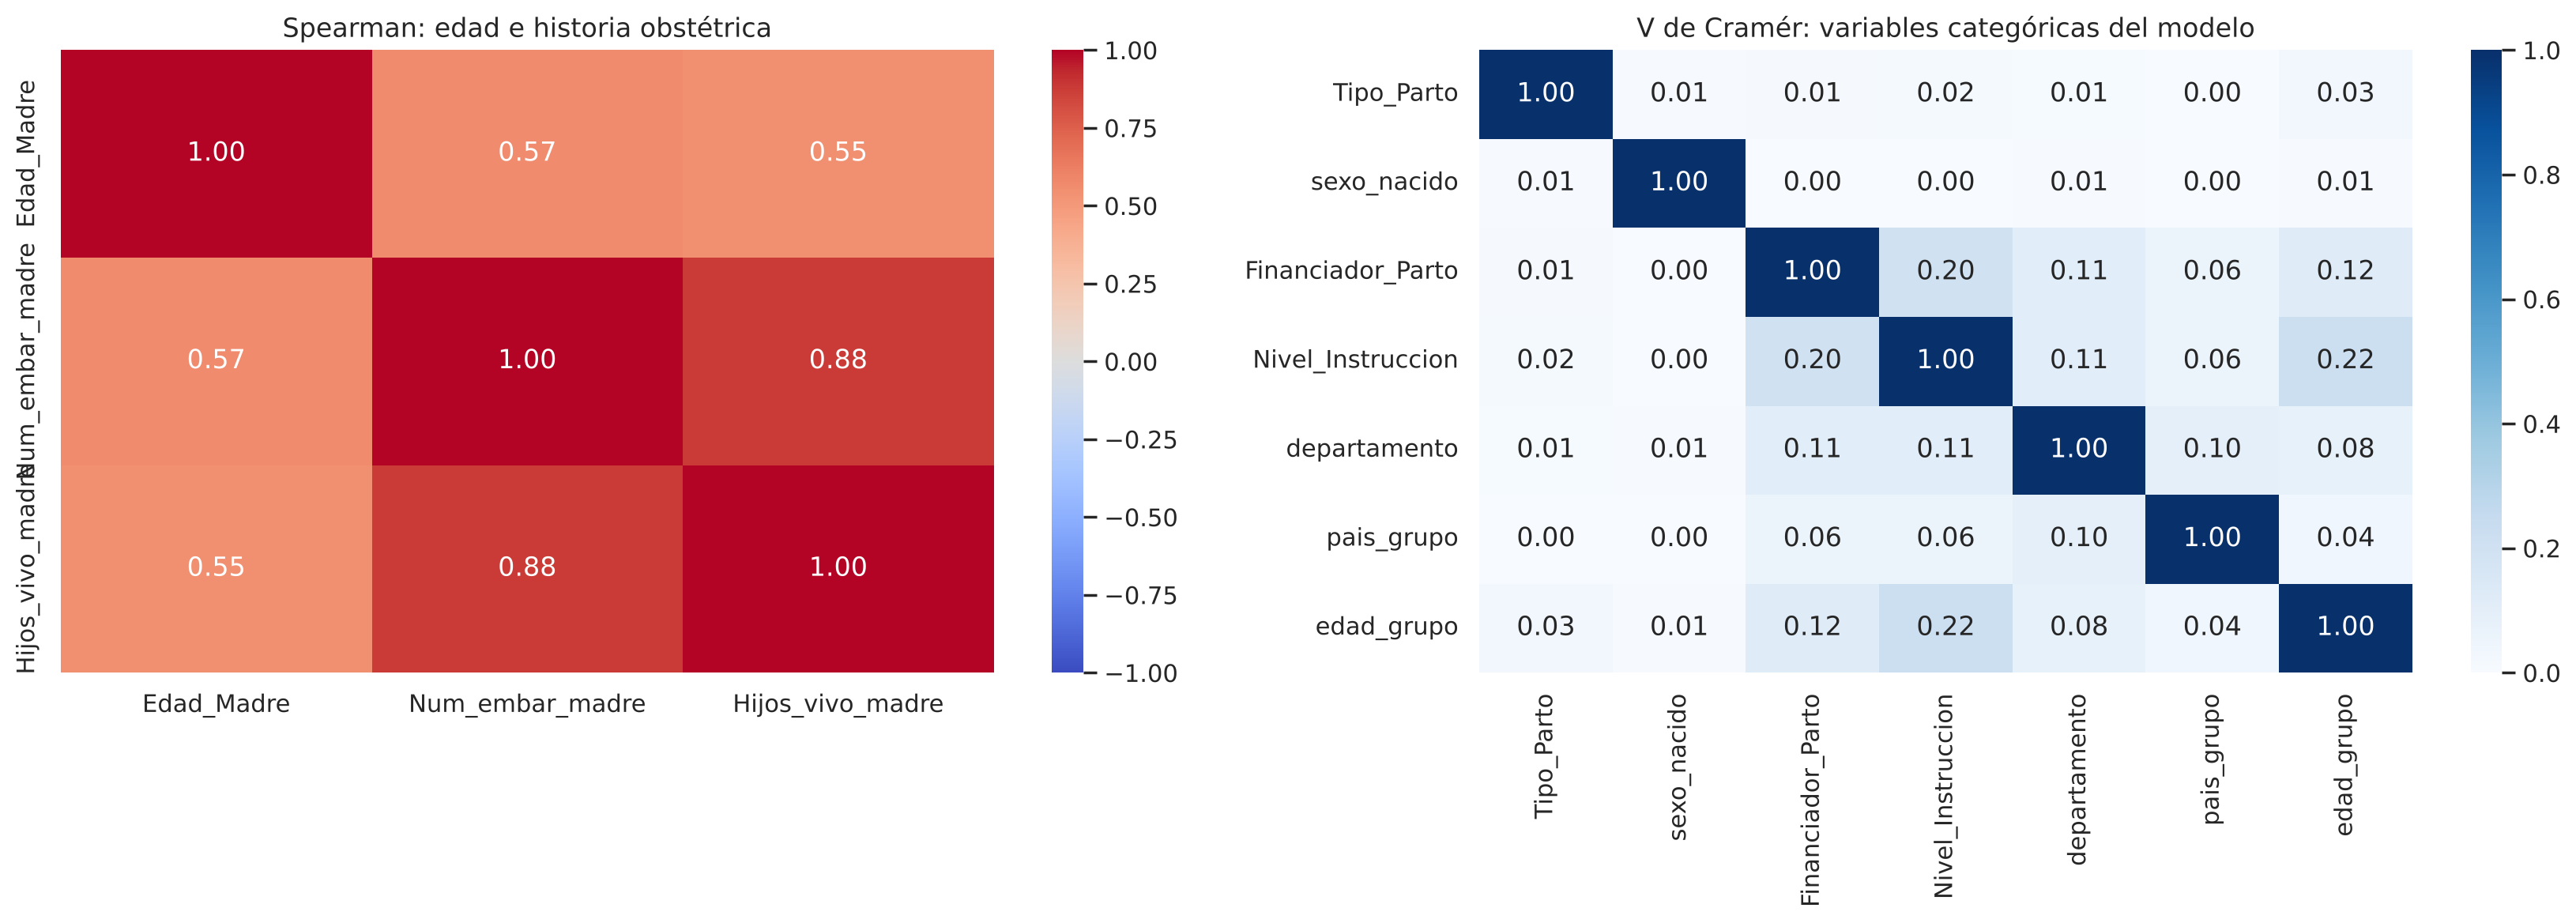

Spearman:
                  Edad_Madre  Num_embar_madre  Hijos_vivo_madre
Edad_Madre             1.000            0.566             0.551
Num_embar_madre        0.566            1.000             0.881
Hijos_vivo_madre       0.551            0.881             1.000

V de Cramér (muestra de 500 000 registros):
                   Tipo_Parto  sexo_nacido  Financiador_Parto  Nivel_Instruccion  departamento  pais_grupo  edad_grupo
Tipo_Parto              1.000        0.010              0.010              0.020         0.010       0.000       0.030
sexo_nacido             0.010        1.000              0.000              0.000         0.010       0.000       0.010
Financiador_Parto       0.010        0.000              1.000              0.200         0.110       0.060       0.120
Nivel_Instruccion       0.020        0.000              0.200              1.000         0.110       0.060       0.220
departamento            0.010        0.010              0.110              0.110         1.000

In [30]:
spear = df_eda[["Edad_Madre"] + paridad].corr(method="spearman")

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

muestra = df_eda.sample(500_000, random_state=42)
# Solo las variables categóricas del modelo (Estado_Civil se excluyó en la sección 4.6)
cv_cols = ["Tipo_Parto", "sexo_nacido", "Financiador_Parto", "Nivel_Instruccion", "departamento", "pais_grupo", "edad_grupo"]
cv = pd.DataFrame(index=cv_cols, columns=cv_cols, dtype=float)
for a in cv_cols:
    for b in cv_cols:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(muestra[a], muestra[b])

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(spear, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Spearman: edad e historia obstétrica")
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("V de Cramér: variables categóricas del modelo")
guardar("relaciones_features")
print("Spearman:"); print(spear.round(3).to_string())
print("\nV de Cramér (muestra de 500 000 registros):"); print(cv.round(2).to_string())


**Interpretación** (valores de las matrices impresas):
- **`Num_embar_madre` y `Hijos_vivo_madre` son redundantes**, con una correlación de Spearman de ρ = 0.88. `Num_embar_madre` aporta algo más por sí sola (AUC de 0.531 frente a 0.524; ver sección 9).

  **Decisión:** se conserva solo `Num_embar_madre`, que contiene casi toda la información de ambas. Es la misma elección que hace Almeida et al. (2026), que usa una sola variable de paridad.
- La edad y la paridad se correlacionan moderadamente (ρ = 0.57 con `Num_embar_madre` y 0.55 con `Hijos_vivo_madre`). No es redundancia, así que se mantienen.
- Entre las variables categóricas del modelo, todas las asociaciones son débiles (V de Cramér ≤ 0.22). Las más altas son nivel de instrucción con grupo de edad (0.22) y con financiador (0.20). `pais_grupo` se asocia poco con las demás: 0.10 con departamento, 0.06 con financiador y con nivel de instrucción, y 0.04 con edad. Por eso su razón ajustada de la sección 7.2 no se explica por esas variables. Cada variable aporta información distinta.


## 9. Poder explicativo de la duración del embarazo

`DUR_EMB_PARTO` es una entrada del modelo y, por mucho, la variable dominante. Esta sección cuantifica cuánto domina, para justificar por qué la asociación de las demás variables se evalúa **condicionada a ella** (sección 7.2).

**Limitación que se declara.** La edad gestacional se estima durante el embarazo (por la fecha de última menstruación o por ecografía), pero el CNV registra su valor final al momento del parto. Es justamente el dato que más información aporta sobre el bajo peso. Además, el Boletín CNV 16 del MINSA indica que se cuenta desde el primer día de la última menstruación, pero no documenta qué método se usó en cada registro. Por eso el modelo trabaja con información conocida **al momento del parto, no antes**.

Se compara su poder discriminante (AUC-ROC de la variable sola) con el de las demás. Es una medida **descriptiva**: no decide la selección, porque una variable que domina el AUC global oculta a las demás.


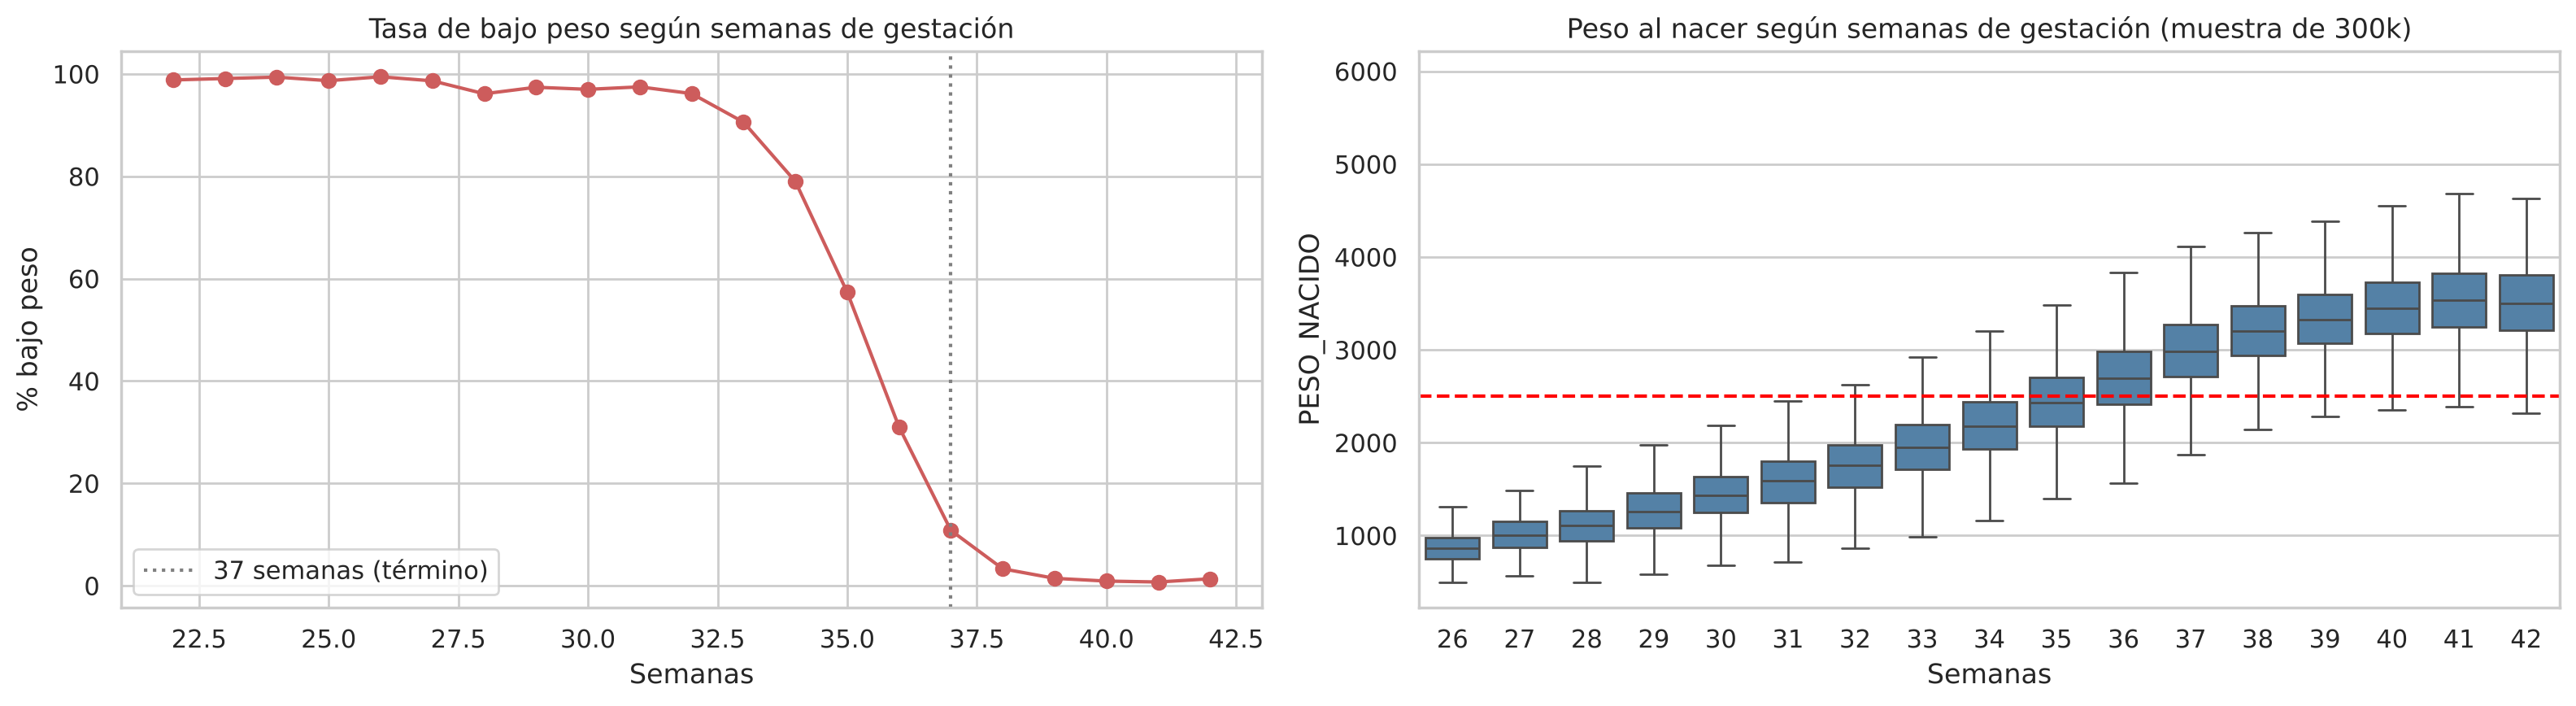

Tasa de bajo peso por semana de gestación (%):
DUR_EMB_PARTO
22.000   98.800
23.000   99.100
24.000   99.400
25.000   98.700
26.000   99.400
27.000   98.600
28.000   96.100
29.000   97.400
30.000   97.000
31.000   97.500
32.000   96.200
33.000   90.600
34.000   79.000
35.000   57.300
36.000   31.000
37.000   10.800
38.000    3.300
39.000    1.400
40.000    0.900
41.000    0.700
42.000    1.300
Partos pretérmino (<37 sem): 6.9% de los registros
Bajo peso en pretérmino:     57.9%
Bajo peso a término (≥37):   2.6%


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
g = df_eda.groupby("DUR_EMB_PARTO")["bajo_peso"].agg(["mean", "count"])
g = g[g["count"] >= 300]
axes[0].plot(g.index, g["mean"] * 100, marker="o", color="indianred")
axes[0].axvline(37, color="gray", ls=":", label="37 semanas (término)")
axes[0].set_title("Tasa de bajo peso según semanas de gestación")
axes[0].set_xlabel("Semanas"); axes[0].set_ylabel("% bajo peso"); axes[0].legend()

m = df_eda[["DUR_EMB_PARTO", "PESO_NACIDO"]].dropna().sample(300_000, random_state=42)
m = m[m["DUR_EMB_PARTO"].between(26, 43)]
sns.boxplot(x=m["DUR_EMB_PARTO"].astype(int), y=m["PESO_NACIDO"], ax=axes[1], color="steelblue", fliersize=0)
axes[1].axhline(2500, color="red", ls="--")
axes[1].set_title("Peso al nacer según semanas de gestación (muestra de 300k)"); axes[1].set_xlabel("Semanas")
guardar("duracion_gestacion")

print("Tasa de bajo peso por semana de gestación (%):")
print((g["mean"] * 100).round(1).to_string())

pre = df_eda["DUR_EMB_PARTO"] < 37
print(f"Partos pretérmino (<37 sem): {pre.mean()*100:.1f}% de los registros")
print(f"Bajo peso en pretérmino:     {df_eda.loc[pre, 'bajo_peso'].mean()*100:.1f}%")
print(f"Bajo peso a término (≥37):   {df_eda.loc[df_eda['DUR_EMB_PARTO'] >= 37, 'bajo_peso'].mean()*100:.1f}%")

In [32]:
def auc_univariado(col):
    """AUC de un clasificador trivial que asigna a cada registro la tasa de bajo peso de su categoría.
    Captura relaciones no lineales (p. ej., la forma en U de la edad). Es descriptivo: no decide la selección."""
    d = df_eda[[col, "bajo_peso"]].dropna()
    score = d.groupby(col, observed=True)["bajo_peso"].transform("mean")
    return roc_auc_score(d["bajo_peso"], score)

cand = ["DUR_EMB_PARTO", "Tipo_Parto", "Edad_Madre", "Nivel_Instruccion", "departamento", "Financiador_Parto",
        "Num_embar_madre", "Hijos_vivo_madre", "sexo_nacido", "Estado_Civil", "pais_grupo", "FecNac_Mes"]
auc_tabla = pd.Series({c: auc_univariado(c) for c in cand}).sort_values(ascending=False).to_frame("AUC_univariado")
excluidas = ["Estado_Civil", "Hijos_vivo_madre", "FecNac_Mes"]   # se muestran como evidencia de su exclusión (secciones 3.1, 4.6 y 8)
auc_tabla["en_modelo"] = np.where(auc_tabla.index.isin(excluidas), "No", "Sí")
auc_tabla


,AUC_univariado,en_modelo
DUR_EMB_PARTO,0.888,Sí
Tipo_Parto,0.576,Sí
Edad_Madre,0.552,Sí
departamento,0.551,Sí
Num_embar_madre,0.531,Sí
Nivel_Instruccion,0.530,Sí
Hijos_vivo_madre,0.524,No
Financiador_Parto,0.520,Sí
sexo_nacido,0.514,Sí
FecNac_Mes,0.505,No


**Interpretación.**
- La edad gestacional explica la mayor parte del bajo peso. El 6.9% de los partos son pretérmino, y entre ellos el bajo peso llega a 57.9%, frente a 2.6% en los partos a término. La tabla por semana muestra que hasta la semana 33 el bajo peso supera el 90%, y desde la semana 38 cae por debajo del 3.5%.
- `DUR_EMB_PARTO` alcanza por sí sola un **AUC de 0.888**. La mejor de las demás, `Tipo_Parto`, llega a 0.576, y el resto está entre 0.50 y 0.55.
- `pais_grupo` tiene un AUC de solo 0.504 pese a la diferencia de tasas de la sección 7, porque afecta a muy pocos registros. Un AUC univariado bajo no significa que una variable sea inútil: mide su capacidad de ordenar a toda la población, no a un subgrupo. `FecNac_Mes` (0.505) no muestra señal marginal.

**Implicaciones:**
1. Como la duración del embarazo es casi un sustituto del resultado, las métricas del modelo serán altas, pero no porque las demás variables predigan bien por sí solas. Por eso su aporte se evalúa condicionando por la duración (sección 7.2) y, en el entrenamiento, con importancia por permutación en validación.
2. La duración se conoce al momento del parto, no antes. La comparación con Almeida et al. (2026), que también la usa, es válida; una predicción estrictamente prenatal requeriría rehacer la selección sin esta variable.
3. El techo del modelo está limitado por las variables que registra el CNV, listadas en la sección 3. Por ejemplo, el dataset usado por Aftab et al. (2026), uno de los papers revisados, incluye visitas prenatales, anemia, hipertensión y aumento de peso materno, y el CNV no registra ninguna de ellas.

*Nota: el AUC univariado se calcula sobre todo el dataset con fines descriptivos. La evaluación de los modelos se hará sobre el test temporal (2024–2025).*


## 10. Conclusiones y decisiones de preprocesamiento

### Hallazgos y decisiones

| # | Hallazgo | Decisión (se implementa en `src/preprocessing.py`) |
|---|---|---|
| 1 | 388 filas con `;` dentro de `DESC_OCUPACION` | Reparar al cargar; no descartar filas |
| 2 | `Hijos_fallec_madre` con 97% de `-1` y significado ambiguo | Excluir |
| 3 | `-1`, `IGNORADO` y `99` son códigos de faltante | Convertir a `NaN` |
| 4 | Faltantes ≤ 1.02% en las 9 features | Eliminación de casos completos (se conserva el 97.81%) |
| 5 | Valores fuera de rango (< 0.1%) | Convertir a `NaN`; eliminar registros sin peso válido |
| 6 | 974 duplicados sin ID que los distinga | Mantener |
| 7 | 0.60% de partos únicos con más hijos vivos que embarazos | Mantener; reportar como limitación |
| 8 | `Estado_Civil` poco creíble; 78.7% faltante en madres de 17 años o menos | Excluir |
| 9 | Prevalencia de 6.38% (1:15) | Estratificar entre entrenamiento y validación; ponderación de clases; métricas recall / F1 / AUC-ROC / AUC-PR |
| 10 | Redondeo de dígitos en 2500 g | Mantener umbral OMS; reportar como limitación |
| 11 | Edad materna con relación en U que casi desaparece al ajustar por duración; queda el grupo de ≤ 17 años | Representarla con grupos de edad (`edad_grupo`) |
| 12 | Categorías raras | Agrupar partos múltiples, sanidades e "inicial" con "ningún nivel" |
| 13 | `Num_embar_madre` y `Hijos_vivo_madre` con ρ = 0.88 | Conservar solo `Num_embar_madre` |
| 14 | Ubigeo con 1892 distritos | Agregar a 25 departamentos; one-hot |
| 15 | `DUR_EMB_PARTO` con AUC de 0.89; se registra al momento del parto | Entrada del modelo; declarar la dependencia. Las demás variables se evalúan condicionadas a ella |
| 16 | Prevalencia de 6.30% (2015–2023) y 6.79% (2024–2025); AUC de la duración estable por año | Partición temporal: entrenamiento y validación 2015–2023, test 2024–2025 |
| 17 | Madres venezolanas con 8.2% de bajo peso frente a 6.3%; razón ajustada de 1.20 (IC 1.19–1.22) que baja con los años (1.37 en 2018; 1.12–1.17 en 2022–2025) y grupo pequeño (2.1%) | Mantener `pais_grupo` (Perú / Venezuela / Otro) por decisión del equipo. Es un atributo sensible: se interpreta como marcador de contexto y no como efecto de la nacionalidad |
| 18 | `nacmuer_abort_madre`: 8.57% de faltantes no aleatorios (de 4.96% a 20.61% según el departamento); causa el 79% de las filas perdidas (89.55% → 97.81% sin ella); su efecto crudo (1.14) cambia de sentido al condicionar por duración (0.87) | Excluir por calidad y costo. Tratar "ignorado" como categoría solo trasladaría el problema de registro al modelo |
| 19 | Las 8 variables distintas de la duración conservan efecto propio tras ajustar por ella (sección 7.2) | Mantenerlas; confirmar su aporte con importancia por permutación en validación |

### Features finales (9)

`DUR_EMB_PARTO`, `Tipo_Parto`, `departamento`, `Edad_Madre` (como `edad_grupo`), `Num_embar_madre`, `Nivel_Instruccion`, `Financiador_Parto`, `sexo_nacido` y `pais_grupo`.

- **Excluidas por el criterio 1 (validez):** `TALLA_NACIDO`, `Atiende_Parto`, `Condicion_Parto`, `Lugar_Nacido` e `Ipress` (esta última también por el criterio 5).
- **Excluidas por el criterio 2 (calidad) o 5 (costo):** `nacmuer_abort_madre`, `Hijos_fallec_madre`, `Estado_Civil` y `DESC_OCUPACION`.
- **Excluida por el criterio 3 (redundancia):** `Hijos_vivo_madre`.
- **Sin uso como predictor:** `FecNac_Año` (solo para la partición temporal) y `FecNac_Mes` (sin señal marginal).
- **Features con cautela en el criterio 1, declaradas:** `Financiador_Parto` (se registra con el certificado) y `sexo_nacido` (característica del recién nacido, conocible por ecografía).

### Limitaciones

El CNV es un registro administrativo, no un instrumento clínico. Tiene errores de digitación (sección 4.3), inconsistencias en la historia obstétrica (4.5), redondeo del peso (5) y variables con validez dudosa, como el estado civil (4.6). Además, no registra variables clínicas que sí usan otros estudios revisados, como visitas prenatales, anemia o hipertensión materna (sección 9). Por eso es esperable que las variables distintas de la duración aporten una capacidad predictiva limitada.

La selección vale mientras `DUR_EMB_PARTO` sea una entrada del modelo, y esa variable se conoce al momento del parto, no antes; una predicción estrictamente anterior al parto requeriría recalcular el criterio 4 sin ella. La razón ajustada de `pais_grupo` baja con los años, así que el test 2024–2025 puede mostrar un riesgo algo menor que el aprendido en entrenamiento. El test no incluye diciembre de 2025. `FecNac_Mes` y la versión agrupada de `DESC_OCUPACION` no se evaluaron con el criterio 4.
